# Integrated Retail Analytics for Store Optimization and Demand Forecasting

**Project type:** EDA, regression and unsupervised learning. **Contribution:** Individual.

**GitHub:** https://github.com/saiabhiram-simhadri/integrated-retail-analytics-store-optimization

## Problem Statement
Analyze weekly store-department sales to identify unusual patterns, examine seasonality and external factors, group stores, study department co-movement and forecast sales. Sales are monetary values. The data does not include customer baskets, stock levels, margins or geographic regions.

## Project Summary
The analysis combines weekly sales, store-week features and store attributes. It covers data quality, exploratory charts, hypothesis tests, anomaly detection, store segmentation, department co-movement and sales forecasting.

Forecasts are evaluated using chronological validation and a final eight-week test. Historical store-department means outperform the tested decision trees and random forests, with test MAE of 2,266.30. A separate 26-week seasonal forecast has MAE of 2,063.45 on an earlier evaluation period; these scores cover different weeks.

K-means selects two store clusters with silhouette 0.345. Department association rules describe simultaneous high sales rather than customer purchases. Missing promotion records and unknown future external inputs limit interpretation. Tables are displayed in the notebook. Charts are saved in `outputs/figures/` and fitted models in `models/`.

## 1. Know Your Data
### Import Libraries
Run the notebook from the repository root, in order. Random seed: 47. The primary forecast metric is MAE in sales currency per store-department-week; success means beating the historical-average baseline on unseen weeks. Charts are saved in `outputs/figures/`; result tables are displayed in the notebook.

In [28]:
%config InlineBackend.figure_format = 'retina'

from pathlib import Path
from itertools import combinations
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, silhouette_score
import joblib
from IPython.display import display

SEED = 47
ROOT = Path.cwd()
OUT = ROOT / "outputs"
FIG = OUT / "figures"
MODEL = ROOT / "models"
for folder in [OUT, FIG, MODEL]:
    folder.mkdir(parents=True, exist_ok=True)
# Use the same dark theme in the notebook and saved figures.
CUSTOM_THEME = {
    "bg": "#18191C",
    "card": "#222428",
    "grid": "#32363C",
    "text": "#E3E5E8",
    "subtext": "#9B9D9E",
    "teal": "#2DD4BF",
    "coral": "#F87171",
    "purple": "#A78BFA",
    "orange": "#FB923C"
}
TEAL = CUSTOM_THEME["teal"]
CORAL = CUSTOM_THEME["coral"]
PURPLE = CUSTOM_THEME["purple"]
ORANGE = CUSTOM_THEME["orange"]
sns.set_theme(style="whitegrid", context="notebook", palette=[TEAL, CORAL, PURPLE, ORANGE])
plt.rcParams.update({
    "figure.figsize": (11, 5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": CUSTOM_THEME["bg"],
    "axes.facecolor": CUSTOM_THEME["card"],
    "savefig.facecolor": CUSTOM_THEME["bg"],
    "savefig.transparent": False,
    "axes.edgecolor": CUSTOM_THEME["grid"],
    "axes.labelcolor": CUSTOM_THEME["text"],
    "xtick.color": CUSTOM_THEME["subtext"],
    "ytick.color": CUSTOM_THEME["subtext"],
    "grid.color": CUSTOM_THEME["grid"],
    "grid.linestyle": "--",
    "grid.alpha": 0.6,
    "text.color": CUSTOM_THEME["text"],
    "legend.facecolor": CUSTOM_THEME["card"],
    "legend.edgecolor": CUSTOM_THEME["grid"],
    "legend.labelcolor": CUSTOM_THEME["text"]
})
# Coral shows negative correlation, dark gray zero, and teal positive.
CORRELATION_CMAP = LinearSegmentedColormap.from_list(
    "retail_dark", [CORAL, CUSTOM_THEME["card"], TEAL]
)

def save_chart(name, title, xlabel=None, ylabel=None):
    # Export the finished figure before displaying and closing it.
    ax = plt.gca()
    fig = ax.figure
    ax.set_title(title, loc="left", pad=14)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    sns.despine(ax=ax)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight", facecolor=CUSTOM_THEME["bg"])
    plt.show()
    plt.close(fig)

print("Python:", sys.version.split()[0])
print("Working directory:", ROOT)

Python: 3.12.1
Working directory: C:\Users\saiab\Desktop\Workspace\Data Science\development\retail-analytics-store-optimization


### Dataset Loading, First View and Quality Checks
Dates use day/month/year. Joins must be many-to-one: each sale matches one store-week feature row and one store row. The holiday columns must agree. Features beyond the sales period are not future sales labels.

In [2]:
sales = pd.read_csv(ROOT / "data/sales.csv")
features = pd.read_csv(ROOT / "data/Features.csv")
stores = pd.read_csv(ROOT / "data/stores.csv")
for frame in [sales, features]:
    frame["Date"] = pd.to_datetime(frame["Date"], format="%d/%m/%Y")
quality = pd.DataFrame({
    "rows": [len(sales), len(features), len(stores)],
    "columns": [sales.shape[1], features.shape[1], stores.shape[1]],
    "duplicate_rows": [sales.duplicated().sum(), features.duplicated().sum(), stores.duplicated().sum()]
}, index=["sales", "features", "stores"])
display(quality)
for name, frame in [("sales", sales), ("features", features), ("stores", stores)]:
    print(name)
    display(frame.head(3))
assert not sales.duplicated(["Store", "Dept", "Date"]).any()
assert not features.duplicated(["Store", "Date"]).any()
assert not stores.duplicated(["Store"]).any()
df = sales.merge(features, on=["Store", "Date"], how="left",
                 suffixes=("", "_features"), validate="many_to_one", indicator=True)
assert df["_merge"].eq("both").all()
assert df["IsHoliday"].eq(df["IsHoliday_features"]).all()
df = df.drop(columns=["_merge", "IsHoliday_features"]).merge(
    stores, on="Store", how="left", validate="many_to_one")
assert len(df) == len(sales)
assert df[["Weekly_Sales", "Type", "Size"]].notna().all().all()
display(df.head())
df.info()
display(df.isna().sum().to_frame("missing"))
print("Period:", df.Date.min(), "to", df.Date.max())
print("Stores:", df.Store.nunique(), "Departments:", df.Dept.nunique())
print("Negative sales:", df.Weekly_Sales.lt(0).sum())

,rows,columns,duplicate_rows
sales,421570,5,0
features,8190,12,0
stores,45,3,0


sales


,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False


features


,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False


...

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392


,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,A,151315


<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[us]
 3   Weekly_Sales  421570 non-null  float64       
 4   IsHoliday     421570 non-null  bool          
 5   Temperature   421570 non-null  float64       
 6   Fuel_Price    421570 non-null  float64       
 7   MarkDown1     150681 non-null  float64       
 8   MarkDown2     111248 non-null  float64       
 9   MarkDown3     137091 non-null  float64       
 10  MarkDown4     134967 non-null  float64       
 11  MarkDown5     151432 non-null  float64       
 12  CPI           421570 non-null  float64       
 13  Unemployment  421570 non-null  float64       
 14  Type          421570 non-null  str           
 15  Size          421570 non-nul

,missing
Store,0
Dept,0
Date,0
Weekly_Sales,0
IsHoliday,0
Temperature,0
Fuel_Price,0
MarkDown1,270889
MarkDown2,310322
MarkDown3,284479


Period: 2010-02-05 00:00:00 to 2012-10-26 00:00:00
Stores: 45 Departments: 81
Negative sales: 1285


## 2. Understanding Your Variables
| Variable | Meaning and use |
|---|---|
| Store, Dept | Identifiers; categories for forecasting |
| Date | Week date; chronological splits and calendar features |
| Weekly_Sales | Monetary sales target; negative entries may represent returns |
| IsHoliday | Supplied holiday-week flag; not a label for every seasonal event |
| Type, Size | Store format and physical size; size units are not documented here |
| MarkDown1–5 | Anonymized promotion fields; missing does not prove no promotion |
| Temperature | Store-week temperature; supplied store-week measurement |
| Fuel_Price, CPI, Unemployment | External economic conditions; associations are not causal effects |

There are no customer IDs, product IDs, basket transactions, margins or inventory quantities. Customer segmentation is therefore implemented as store segmentation, and market basket analysis as an explicitly limited department proxy.

In [3]:
display(df.describe().T)
display(df.nunique().to_frame("unique_values"))

,count,mean,min,25%,50%,75%,max,std
Store,421570.0,22.200546,1.0,11.0,22.0,33.0,45.0,12.785297
Dept,421570.0,44.260317,1.0,18.0,37.0,74.0,99.0,30.492054
Date,421570,2011-06-18 08:30:31.963375,2010-02-05 00:00:00,2010-10-08 00:00:00,2011-06-17 00:00:00,2012-02-24 00:00:00,2012-10-26 00:00:00,NaN
Weekly_Sales,421570.0,15981.258123,-4988.94,2079.65,7612.03,20205.8525,693099.36,22711.183519
Temperature,421570.0,60.090059,-2.06,46.68,62.09,74.28,100.14,18.447931
Fuel_Price,421570.0,3.361027,2.472,2.933,3.452,3.738,4.468,0.458515
MarkDown1,150681.0,7246.420196,0.27,2240.27,5347.45,9210.9,88646.76,8291.221345
MarkDown2,111248.0,3334.628621,-265.76,41.6,192.0,1926.94,104519.54,9475.357325
MarkDown3,137091.0,1439.421384,-29.1,5.08,24.6,103.99,141630.61,9623.07829
MarkDown4,134967.0,3383.168256,0.22,504.22,1481.31,3595.04,67474.85,6292.384031


,unique_values
Store,45
Dept,81
Date,143
Weekly_Sales,359464
IsHoliday,2
Temperature,3528
Fuel_Price,892
MarkDown1,2277
MarkDown2,1499
MarkDown3,1662


## 3. Data Wrangling
Preserve original sales and missing values for audit. Calendar features are known in advance. The chronological training, validation and test blocks are set before modeling; full-period charts below are descriptive only. Segments, anomaly bounds and department thresholds use the training period.

In [4]:
markdown_cols = [f"MarkDown{i}" for i in range(1, 6)]
df = df.sort_values(["Date", "Store", "Dept"]).reset_index(drop=True)
df["Year"] = df.Date.dt.year
df["Month"] = df.Date.dt.month
df["Week"] = df.Date.dt.isocalendar().week.astype(int)
df["Trend"] = (df.Date - df.Date.min()).dt.days // 7
df["MarkdownMissing"] = df[markdown_cols].isna().any(axis=1).astype(int)
df["TotalMarkdown"] = df[markdown_cols].fillna(0).sum(axis=1)
# Two 8-week validation blocks, then a final untouched 8-week test.
dates = np.sort(df.Date.unique())
test_start = pd.Timestamp(dates[-8])
val_start = pd.Timestamp(dates[-24])
train = df[df.Date < val_start].copy()
validation = df[(df.Date >= val_start) & (df.Date < test_start)].copy()
test = df[df.Date >= test_start].copy()
split_summary = pd.DataFrame([
    [name, len(part), part.Date.nunique(), part.Date.min(), part.Date.max()]
    for name, part in [("train", train), ("validation", validation), ("test", test)]
], columns=["split", "rows", "weeks", "start", "end"])
display(split_summary)
store_week = df.groupby(["Store", "Date"], as_index=False).agg(
    Weekly_Sales=("Weekly_Sales", "sum"), IsHoliday=("IsHoliday", "first"),
    Type=("Type", "first"), Size=("Size", "first"), Temperature=("Temperature", "first"),
    Fuel_Price=("Fuel_Price", "first"), CPI=("CPI", "first"),
    Unemployment=("Unemployment", "first"), TotalMarkdown=("TotalMarkdown", "first"))
weekly = df.groupby("Date").Weekly_Sales.sum()
print("Markdown totals count each store-week once in promotion analyses.")

,split,rows,weeks,start,end
0,train,350595,119,2010-02-05,2012-05-11
1,validation,47246,16,2012-05-18,2012-08-31
2,test,23729,8,2012-09-07,2012-10-26


Markdown totals count each store-week once in promotion analyses.


## 4. Exploratory Data Analysis
Ten exploratory charts cover missingness, sales distribution, weekly and monthly trends, holidays, departments, store size, promotions, correlations and relationships by store type. Five further charts cover anomalies, segmentation, department co-movement and forecast evaluation. Sales and promotions are aggregated at their respective observation levels.

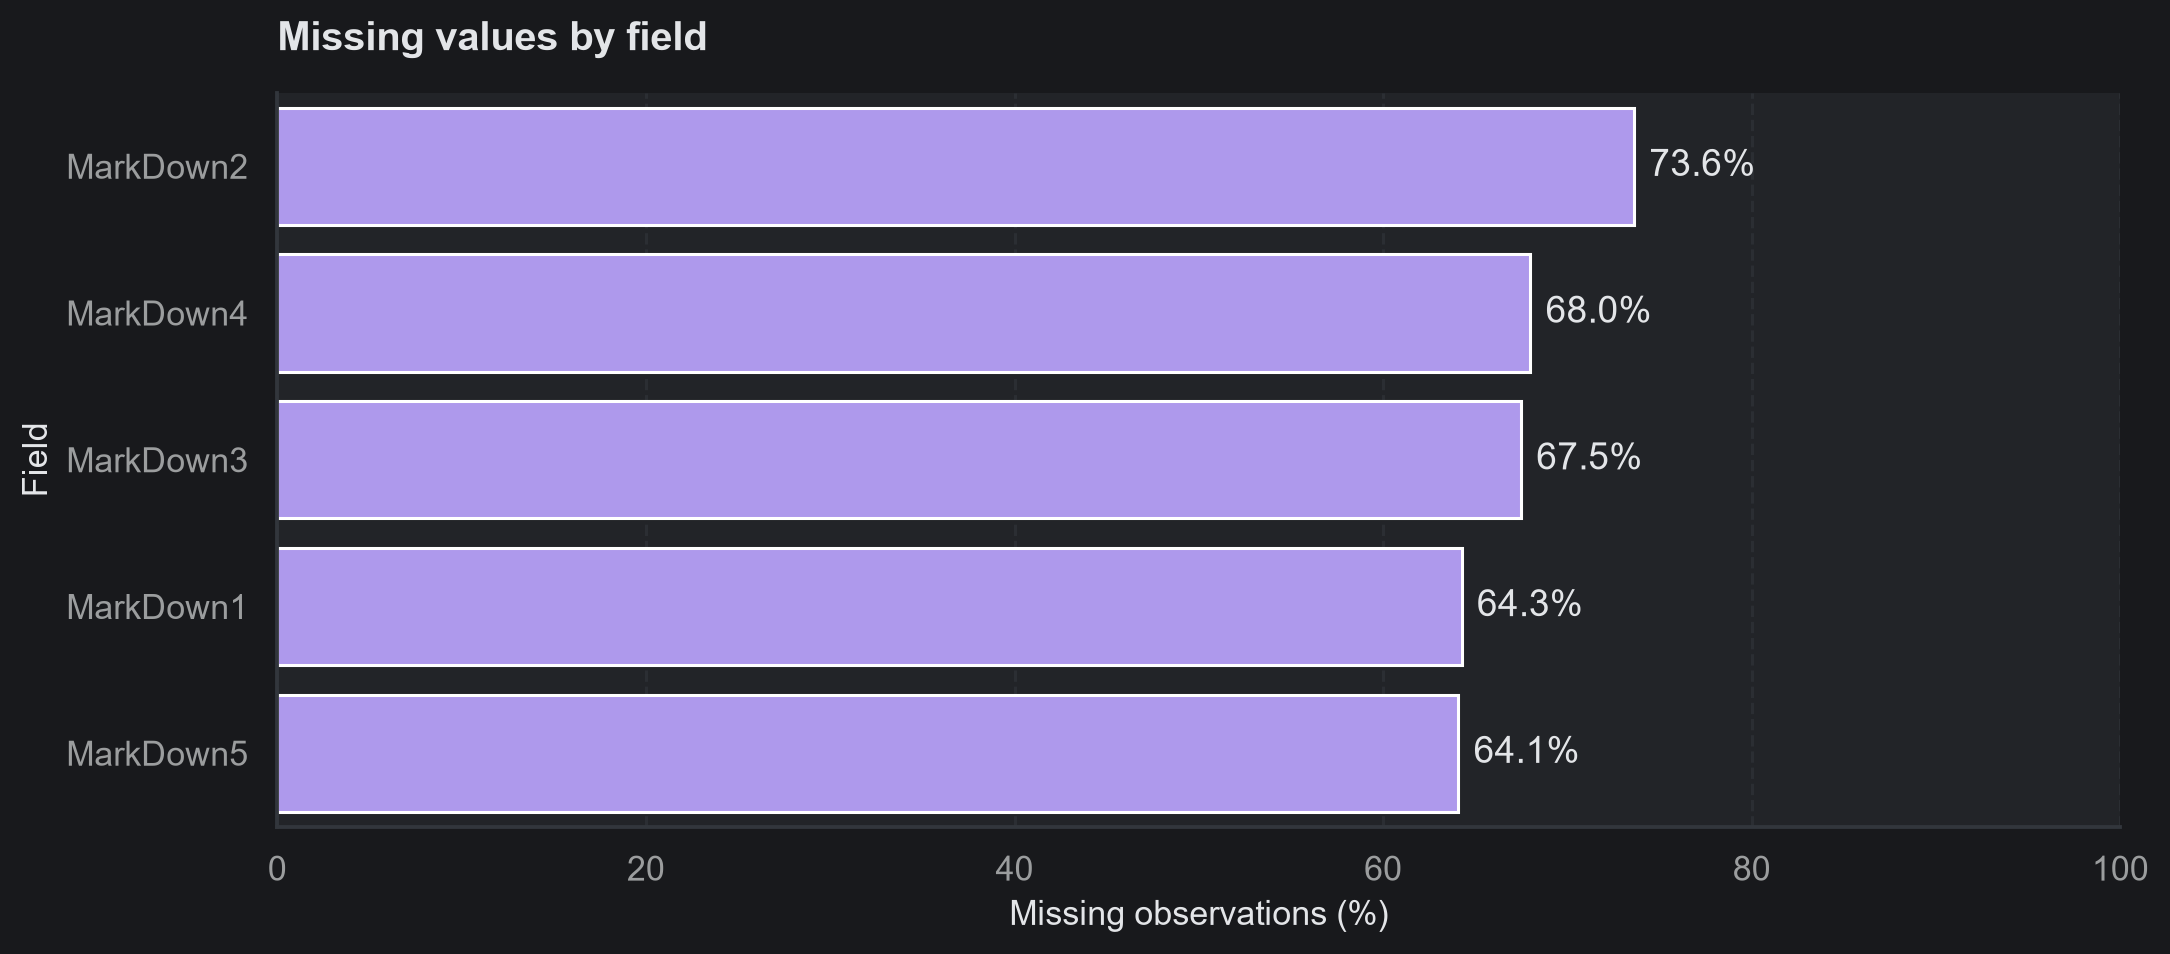

In [29]:
# Missing promotion records, ordered from most to least missing.
missing = df.isna().mean().mul(100).sort_values(ascending=False)
missing_plot = missing[missing > 0].rename_axis("Variable").reset_index(name="MissingPercent")
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=missing_plot, x="MissingPercent", y="Variable", color=PURPLE, ax=ax)
ax.bar_label(ax.containers[0], labels=[f"{value:.1f}%" for value in missing_plot.MissingPercent], padding=5)
ax.set_xlim(0, 100)
ax.xaxis.grid(True)
ax.yaxis.grid(False)
save_chart("01_missingness", "Missing values by field", xlabel="Missing observations (%)", ylabel="Field")

#### 1. Why did you pick the specific chart?

A bar chart makes it easy to compare the percentage of missing observations across columns. It highlights which variables need preprocessing before any relationships or forecasting results are interpreted.

#### 2. What is/are the insight(s) found from the chart?

MarkDown2 has the highest missing share, at 73.6%. Several promotion fields have substantial gaps, so analyses using only reported markdowns represent a limited part of the sales history. A missing entry cannot establish that the store ran no promotion.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This finding supports keeping a markdown missingness indicator alongside the practical zero-fill assumption. Better promotion reporting would make campaign comparisons more useful. Treating every missing entry as confirmed zero spending could produce misleading conclusions and poorly targeted promotions.

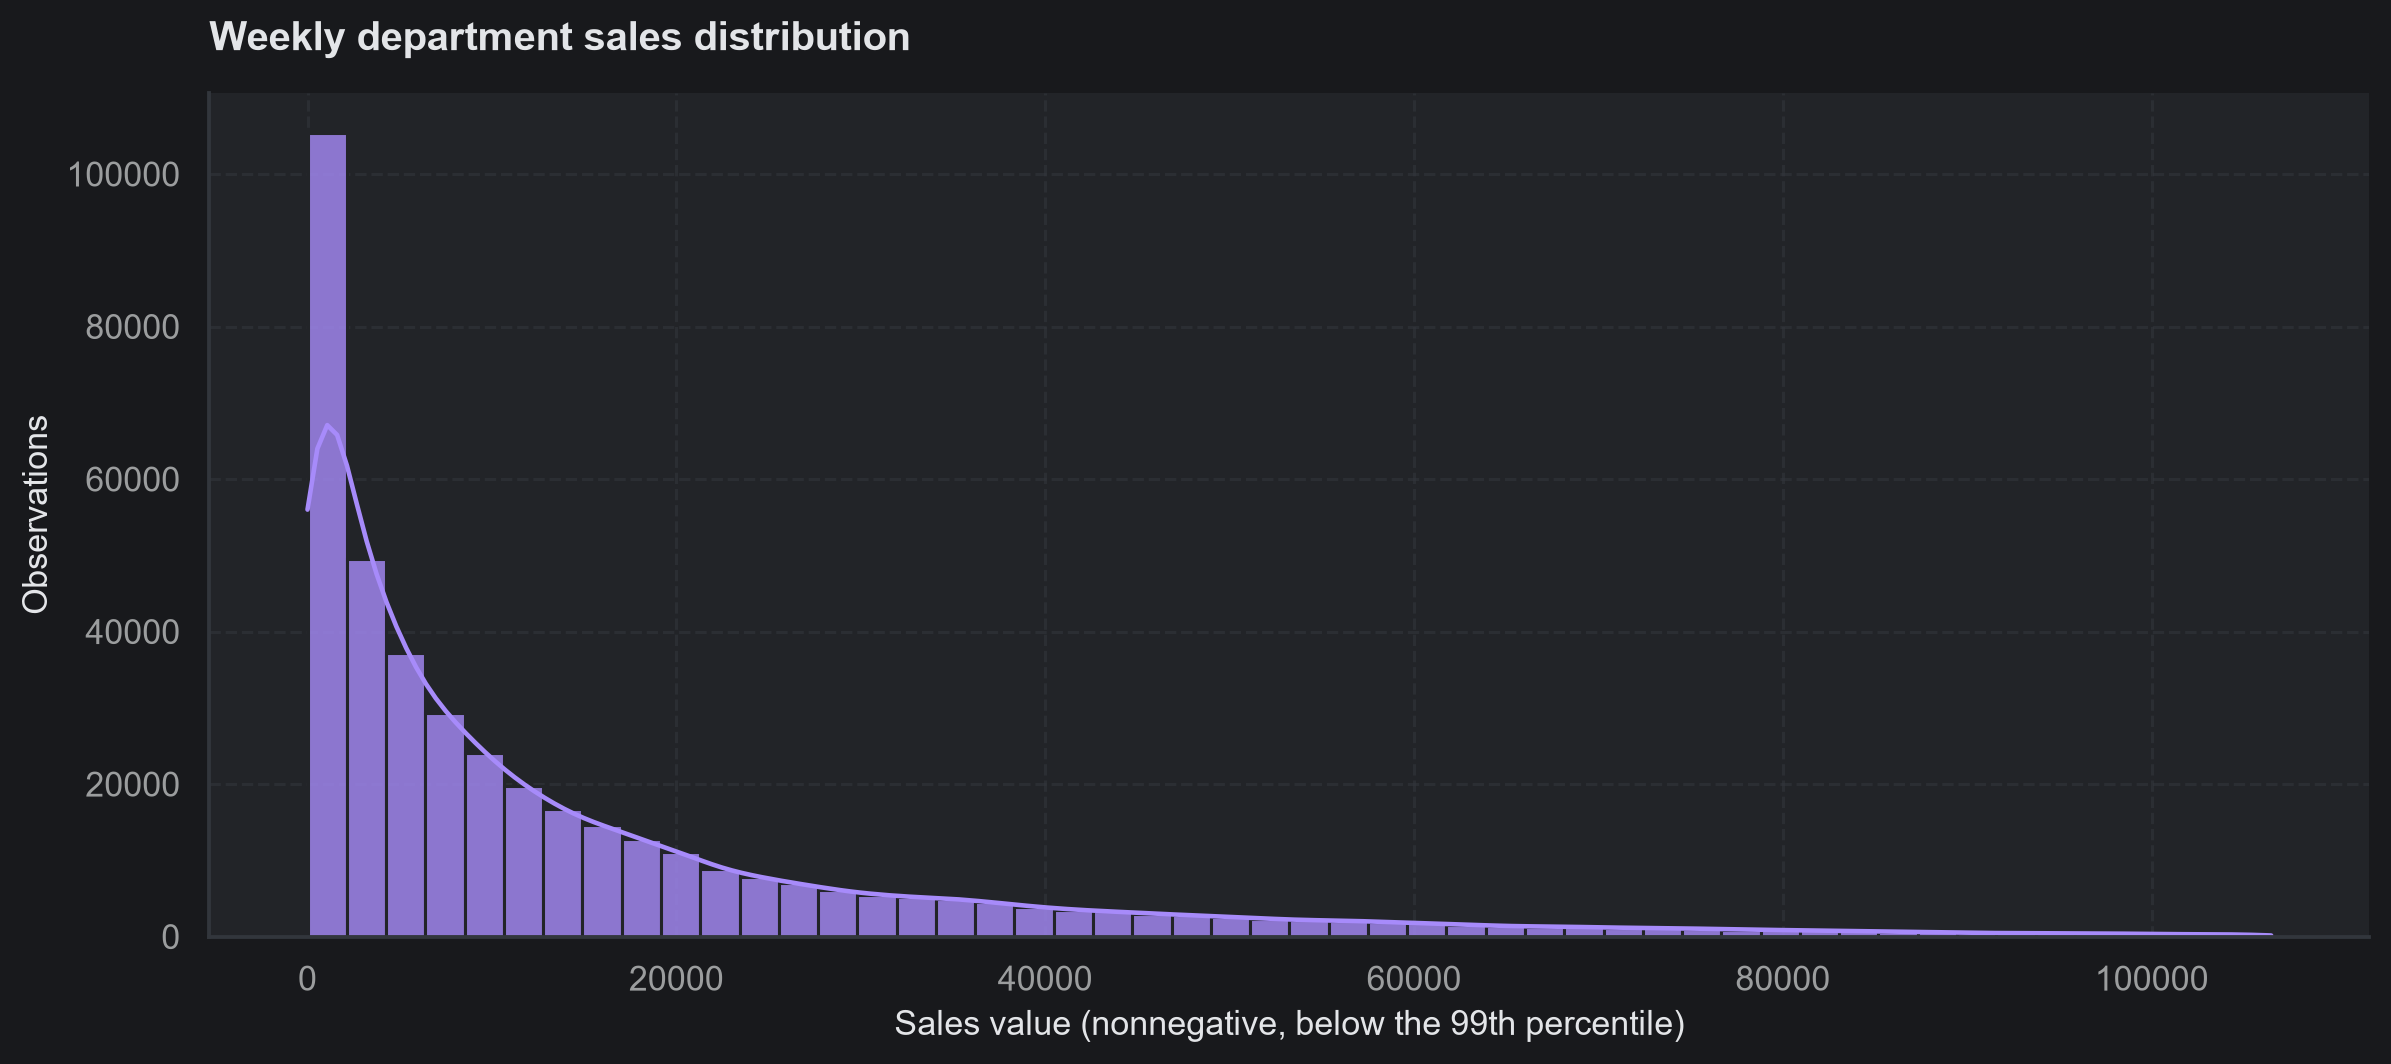

In [30]:
# Limit only the displayed range; keep all observations in the analysis.
upper_plot = df.Weekly_Sales.quantile(.99)
fig, ax = plt.subplots()
sns.histplot(df.loc[df.Weekly_Sales.between(0, upper_plot), "Weekly_Sales"],
             bins=50, kde=True, color=PURPLE, edgecolor=CUSTOM_THEME["card"], alpha=.8, ax=ax)
ax.ticklabel_format(style="plain", axis="x")
save_chart("02_sales_distribution", "Weekly department sales distribution",
           xlabel="Sales value (nonnegative, below the 99th percentile)", ylabel="Observations")

#### 1. Why did you pick the specific chart?

A histogram shows how frequently different sales values occur and whether the distribution is symmetric or skewed. The display focuses on nonnegative sales below the 99th percentile so that typical department-week values remain visible.

#### 2. What is/are the insight(s) found from the chart?

Median weekly sales are 7,612, while the mean is 15,981. This difference is consistent with a right-skewed distribution in which a smaller number of high-sales observations raise the average. Negative sales and the largest observations remain in the dataset even though they are outside this chart's display range.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

The difference between typical and average sales supports planning separately for departments with different sales levels. Using the overall mean as a stock target could overstock smaller departments while failing to reflect the needs of larger ones. Sales values also need prices and product information before they can be converted into inventory units.

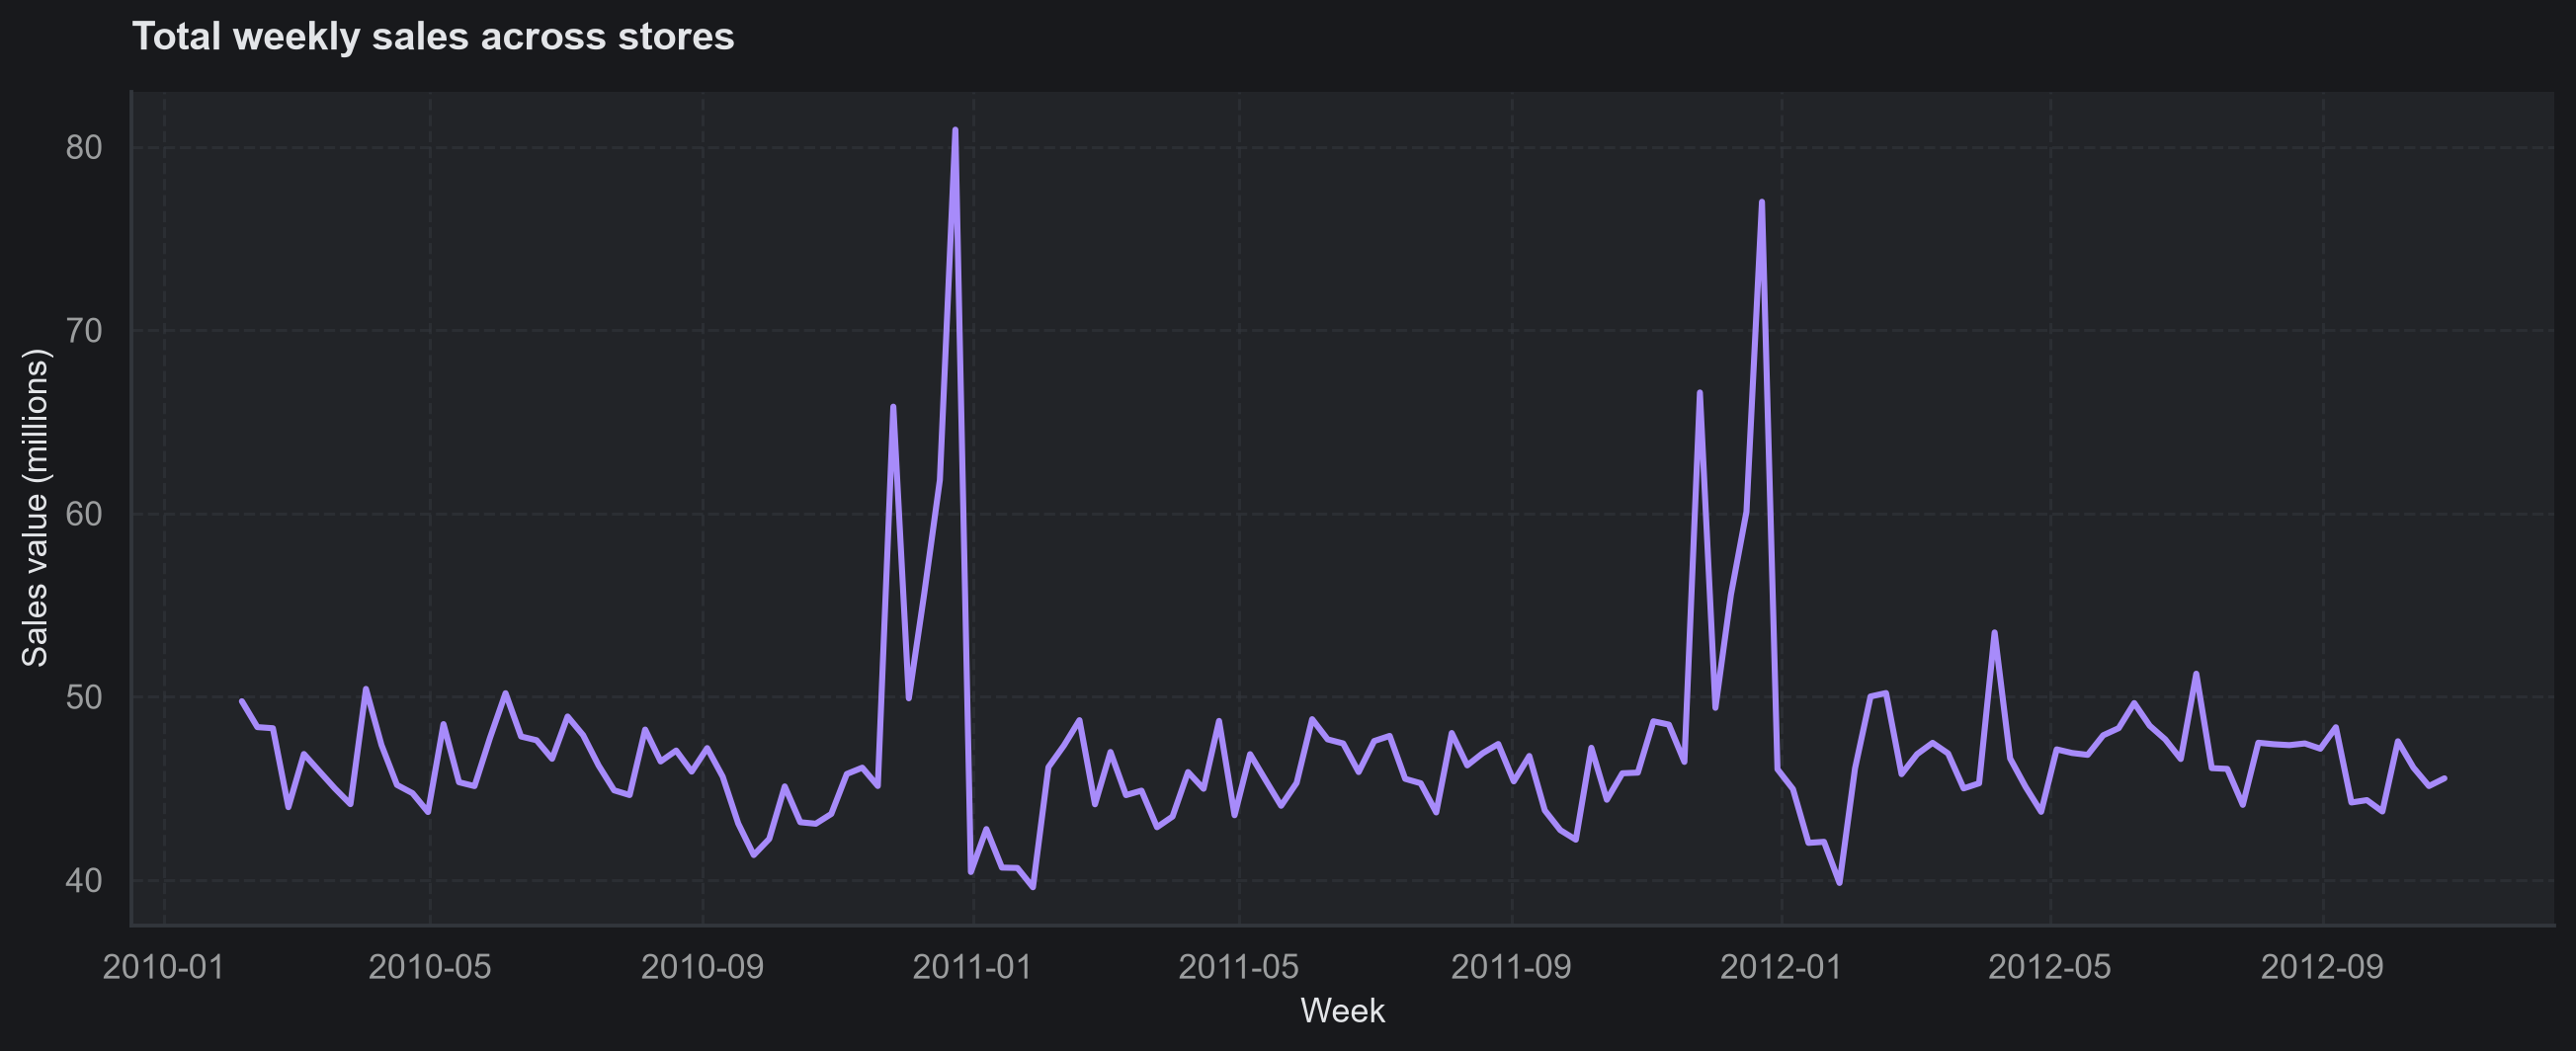

In [31]:
# Show chain sales in millions to keep the axis readable.
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(x=weekly.index, y=weekly.to_numpy() / 1e6, color=PURPLE, linewidth=2, ax=ax)
save_chart("04_weekly_sales", "Total weekly sales across stores", xlabel="Week", ylabel="Sales value (millions)")

#### 1. Why did you pick the specific chart?

A line chart preserves the order of the weekly observations and makes peaks, declines and repeated seasonal patterns easier to follow. Aggregating to the chain level provides an overview before examining individual stores and departments.

#### 2. What is/are the insight(s) found from the chart?

The highest-sales week ends on 24 December 2010, with total sales of 80,931,416. Its timing is consistent with a possible Christmas-period peak, although the chart alone cannot establish the cause. The visible variation shows that weekly sales do not stay at a constant level.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Managers can use the timing of recurring peaks to review staffing, delivery capacity and inventory availability in advance. However, one unusually high week should not be treated as permanent growth or automatically removed as a data error. Planning to sustain peak-week volumes throughout the year could create excess inventory and costs.

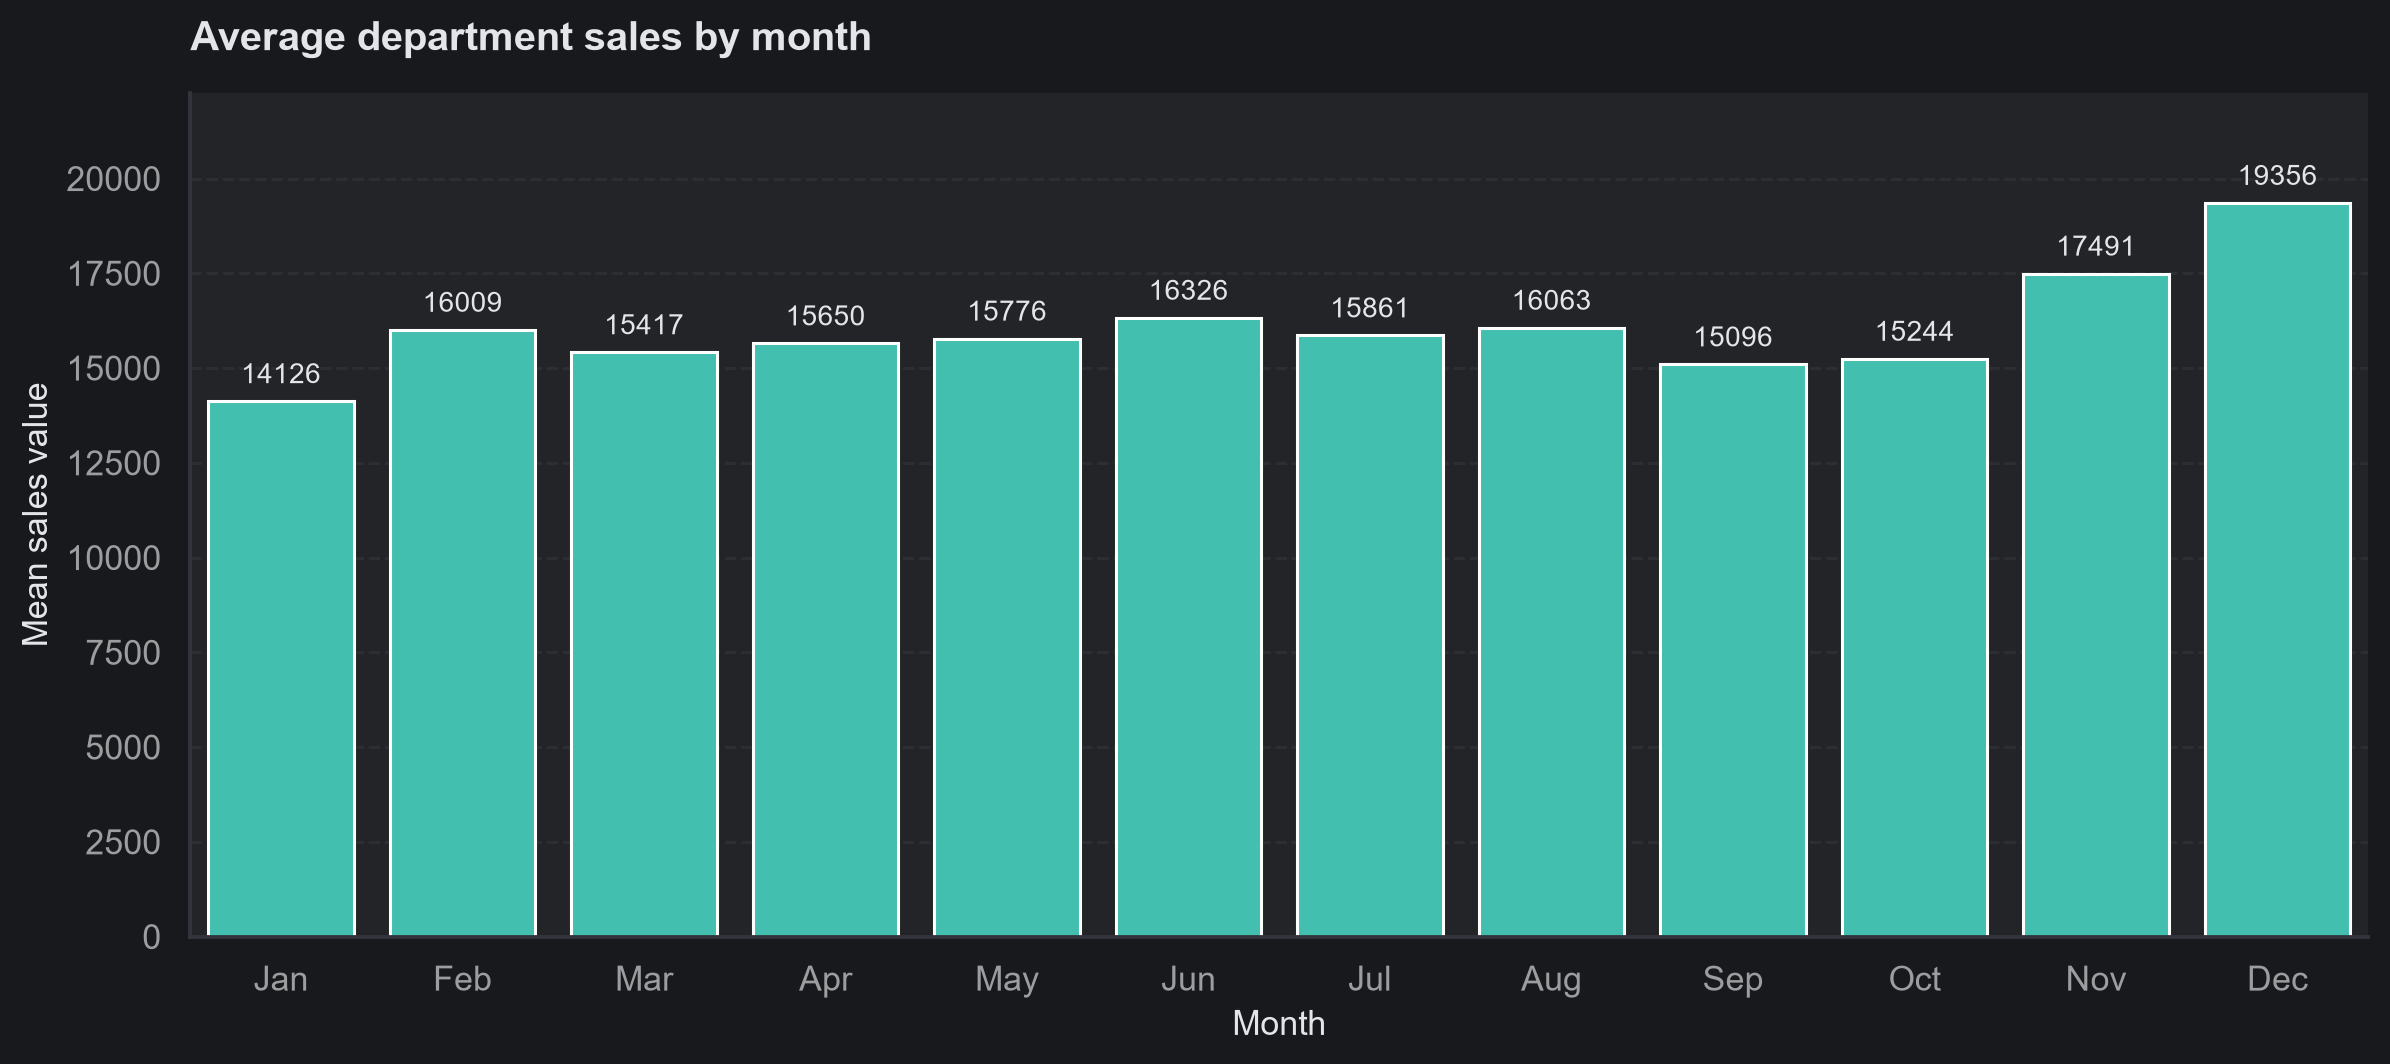

In [32]:
# Monthly averages account for unequal numbers of observed weeks.
monthly = df.groupby("Month").Weekly_Sales.mean()
fig, ax = plt.subplots()
sns.barplot(x=monthly.index, y=monthly.to_numpy(), color=TEAL, ax=ax)
ax.set_xticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.bar_label(ax.containers[0], fmt="%.0f", padding=4, fontsize=9)
ax.margins(y=.15)
save_chart("05_monthly_sales", "Average department sales by month", xlabel="Month", ylabel="Mean sales value")

#### 1. Why did you pick the specific chart?

A bar chart of monthly mean sales makes calendar differences easy to compare. Means are more appropriate here than monthly totals because the dataset contains unequal numbers of observed weeks across months.

#### 2. What is/are the insight(s) found from the chart?

December has the highest mean department-week sales, at approximately 19,356. This agrees with the strong year-end peak in the weekly chart and suggests that calendar timing matters for sales planning. However, the data contains incomplete years, so the month comparisons are not based on identical yearly coverage.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Seasonal planning can increase availability before stronger periods and reduce commitments during quieter periods. Managers should confirm the pattern within their own store and department before applying it. Extending a chain-level December uplift to every department could overstock categories that do not share the pattern.

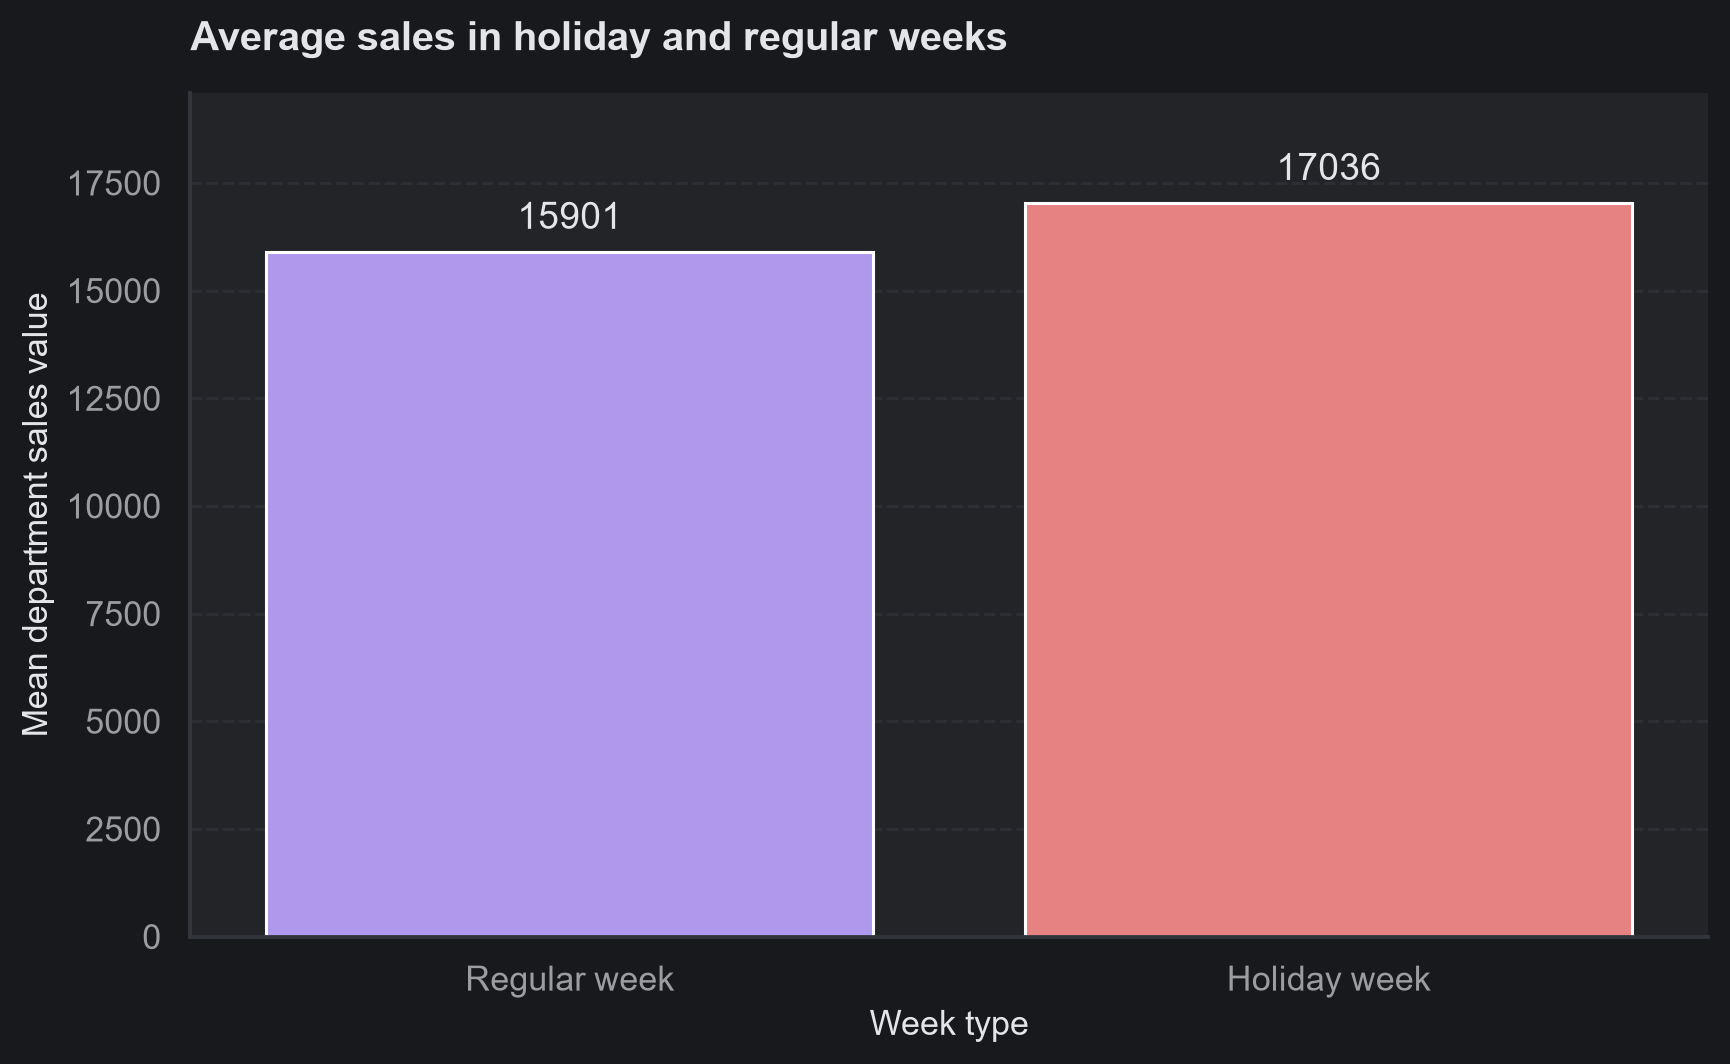

In [33]:
# Compare averages, rather than totals, for the supplied holiday flag.
holiday_mean = df.groupby("IsHoliday").Weekly_Sales.mean()
holiday_plot = holiday_mean.rename_axis("IsHoliday").reset_index(name="MeanSales")
holiday_plot["WeekType"] = holiday_plot.IsHoliday.map({False: "Regular week", True: "Holiday week"})
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=holiday_plot, x="WeekType", y="MeanSales", hue="WeekType",
            palette=[PURPLE, CORAL], legend=False, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=5)
ax.bar_label(ax.containers[1], fmt="%.0f", padding=5)
ax.margins(y=.15)
save_chart("06_holiday_sales", "Average sales in holiday and regular weeks",
           xlabel="Week type", ylabel="Mean department sales value")

#### 1. Why did you pick the specific chart?

A bar chart provides a direct comparison of mean department-week sales for the two supplied holiday groups. Using means avoids interpreting a larger number of ordinary weeks as evidence that they have stronger sales per observation.

#### 2. What is/are the insight(s) found from the chart?

The holiday mean is approximately 17,036, compared with 15,901 for nonholiday weeks. Holiday-flagged observations therefore have higher average sales in this dataset. The comparison is unadjusted and does not separate the holiday flag from seasonal timing, promotion activity or department mix.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This pattern supports reviewing stock and staffing plans before the supplied holiday periods. The increase should be checked at the relevant store-department level rather than used as a uniform uplift. Assuming that every holiday or department has the same response could increase holding costs or leave high-demand categories short.

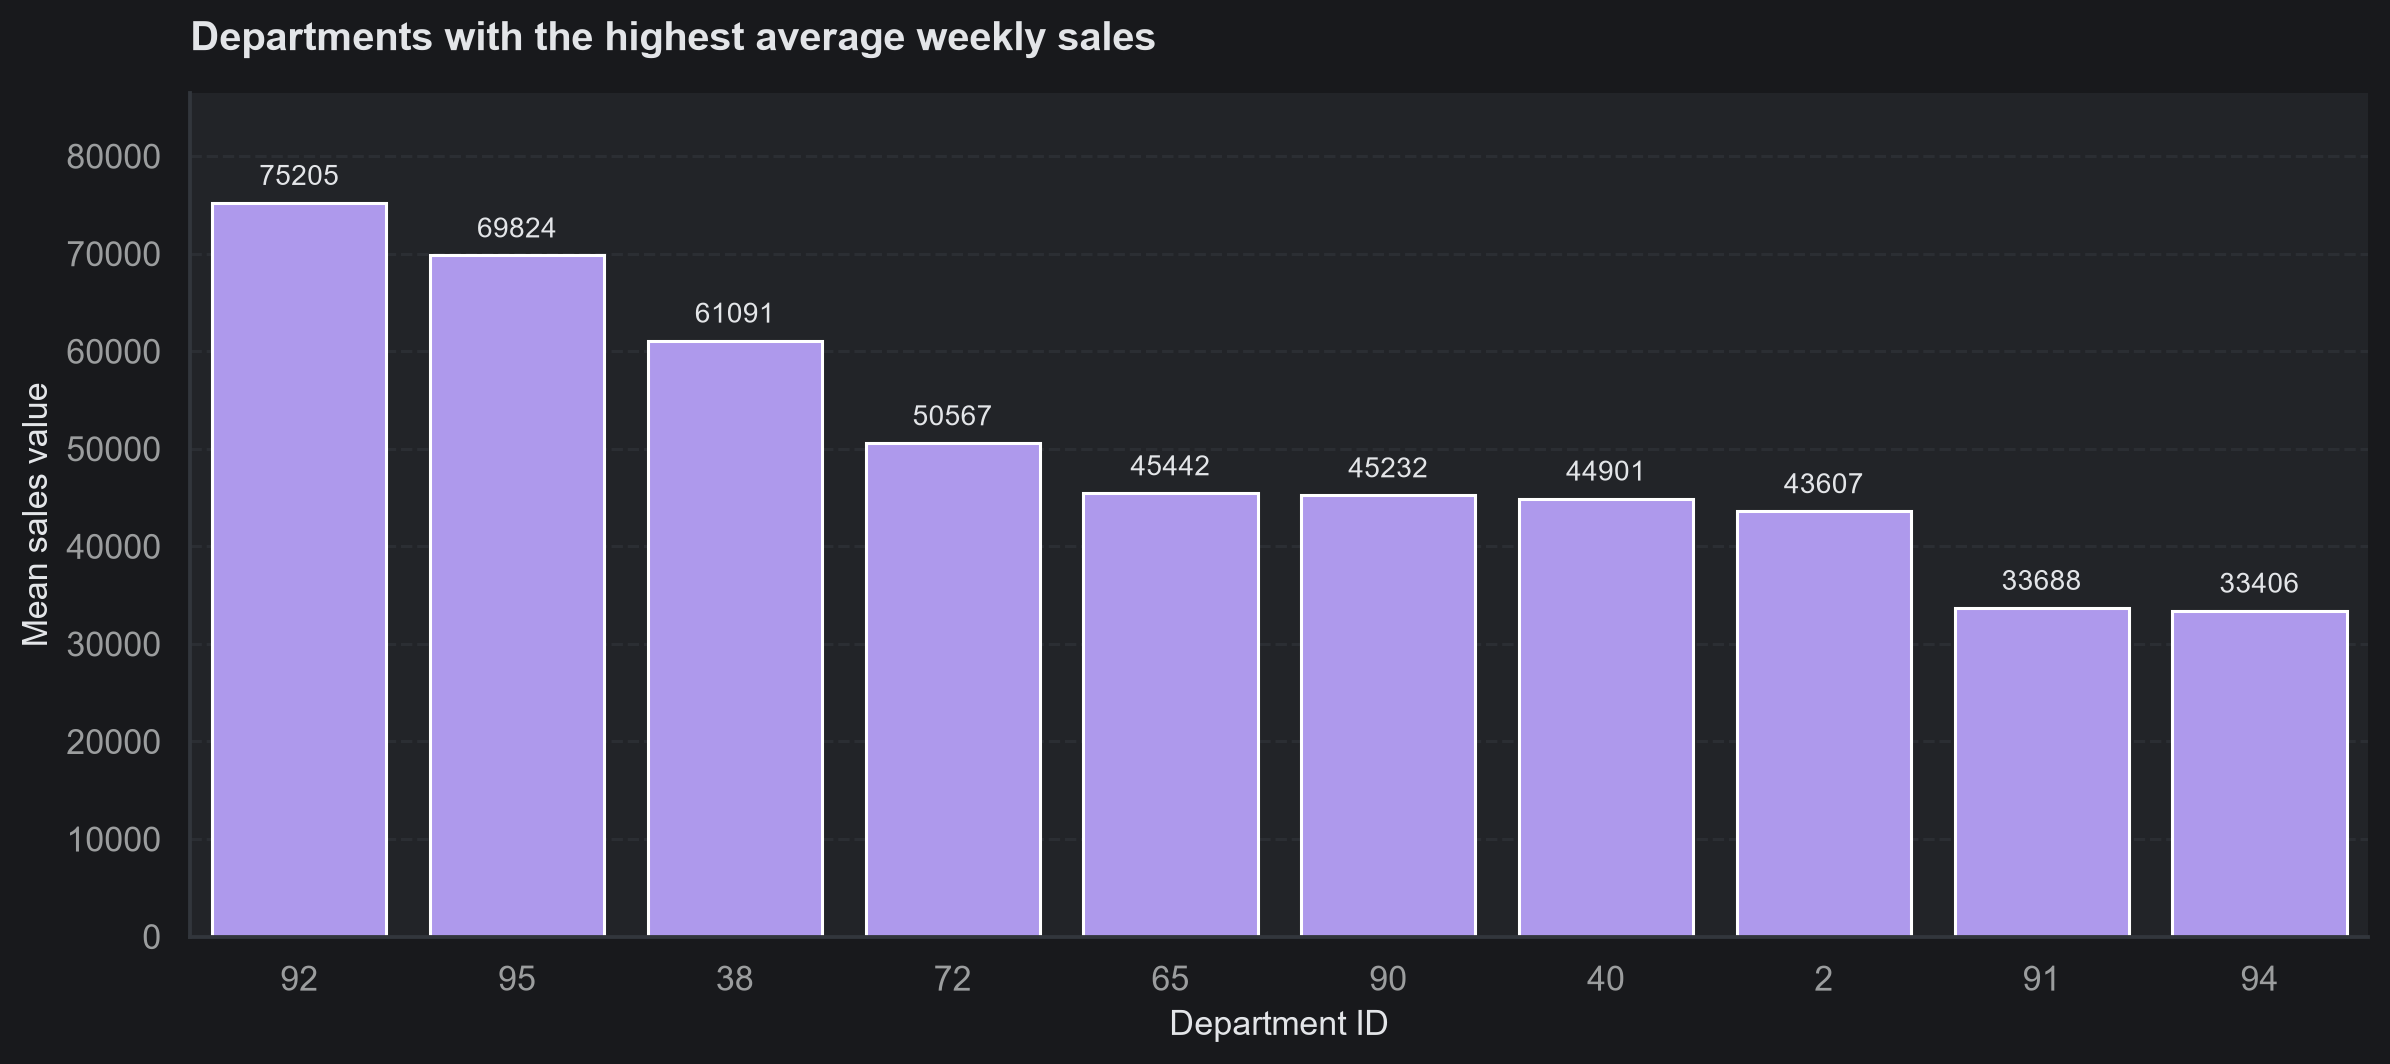

In [34]:
# Rank departments by average sales, keeping their anonymized IDs.
dept_sales = df.groupby("Dept").Weekly_Sales.mean().sort_values(ascending=False)
top_departments = dept_sales.head(10)
fig, ax = plt.subplots()
sns.barplot(x=top_departments.index.astype(str), y=top_departments.to_numpy(), color=PURPLE, ax=ax)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=4, fontsize=9)
ax.margins(y=.15)
save_chart("08_top_departments", "Departments with the highest average weekly sales",
           xlabel="Department ID", ylabel="Mean sales value")

#### 1. Why did you pick the specific chart?

A ranked bar chart highlights departments with the largest average weekly sales. It is easier to compare the leading departments in this view than in a chart containing every department ID.

#### 2. What is/are the insight(s) found from the chart?

Department 92 has the highest mean sales, at approximately 75,205 per observed store-department-week. This identifies a department with a large sales-value contribution at the observation level. The anonymized department ID does not reveal its product category, margin or sales in physical units.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Large-sales departments are useful starting points for reviewing stock availability and forecast errors. Managers need actual category names, prices and margins before deciding how much inventory or promotional budget to allocate. Prioritizing revenue alone could increase investment in a department with relatively low profit.

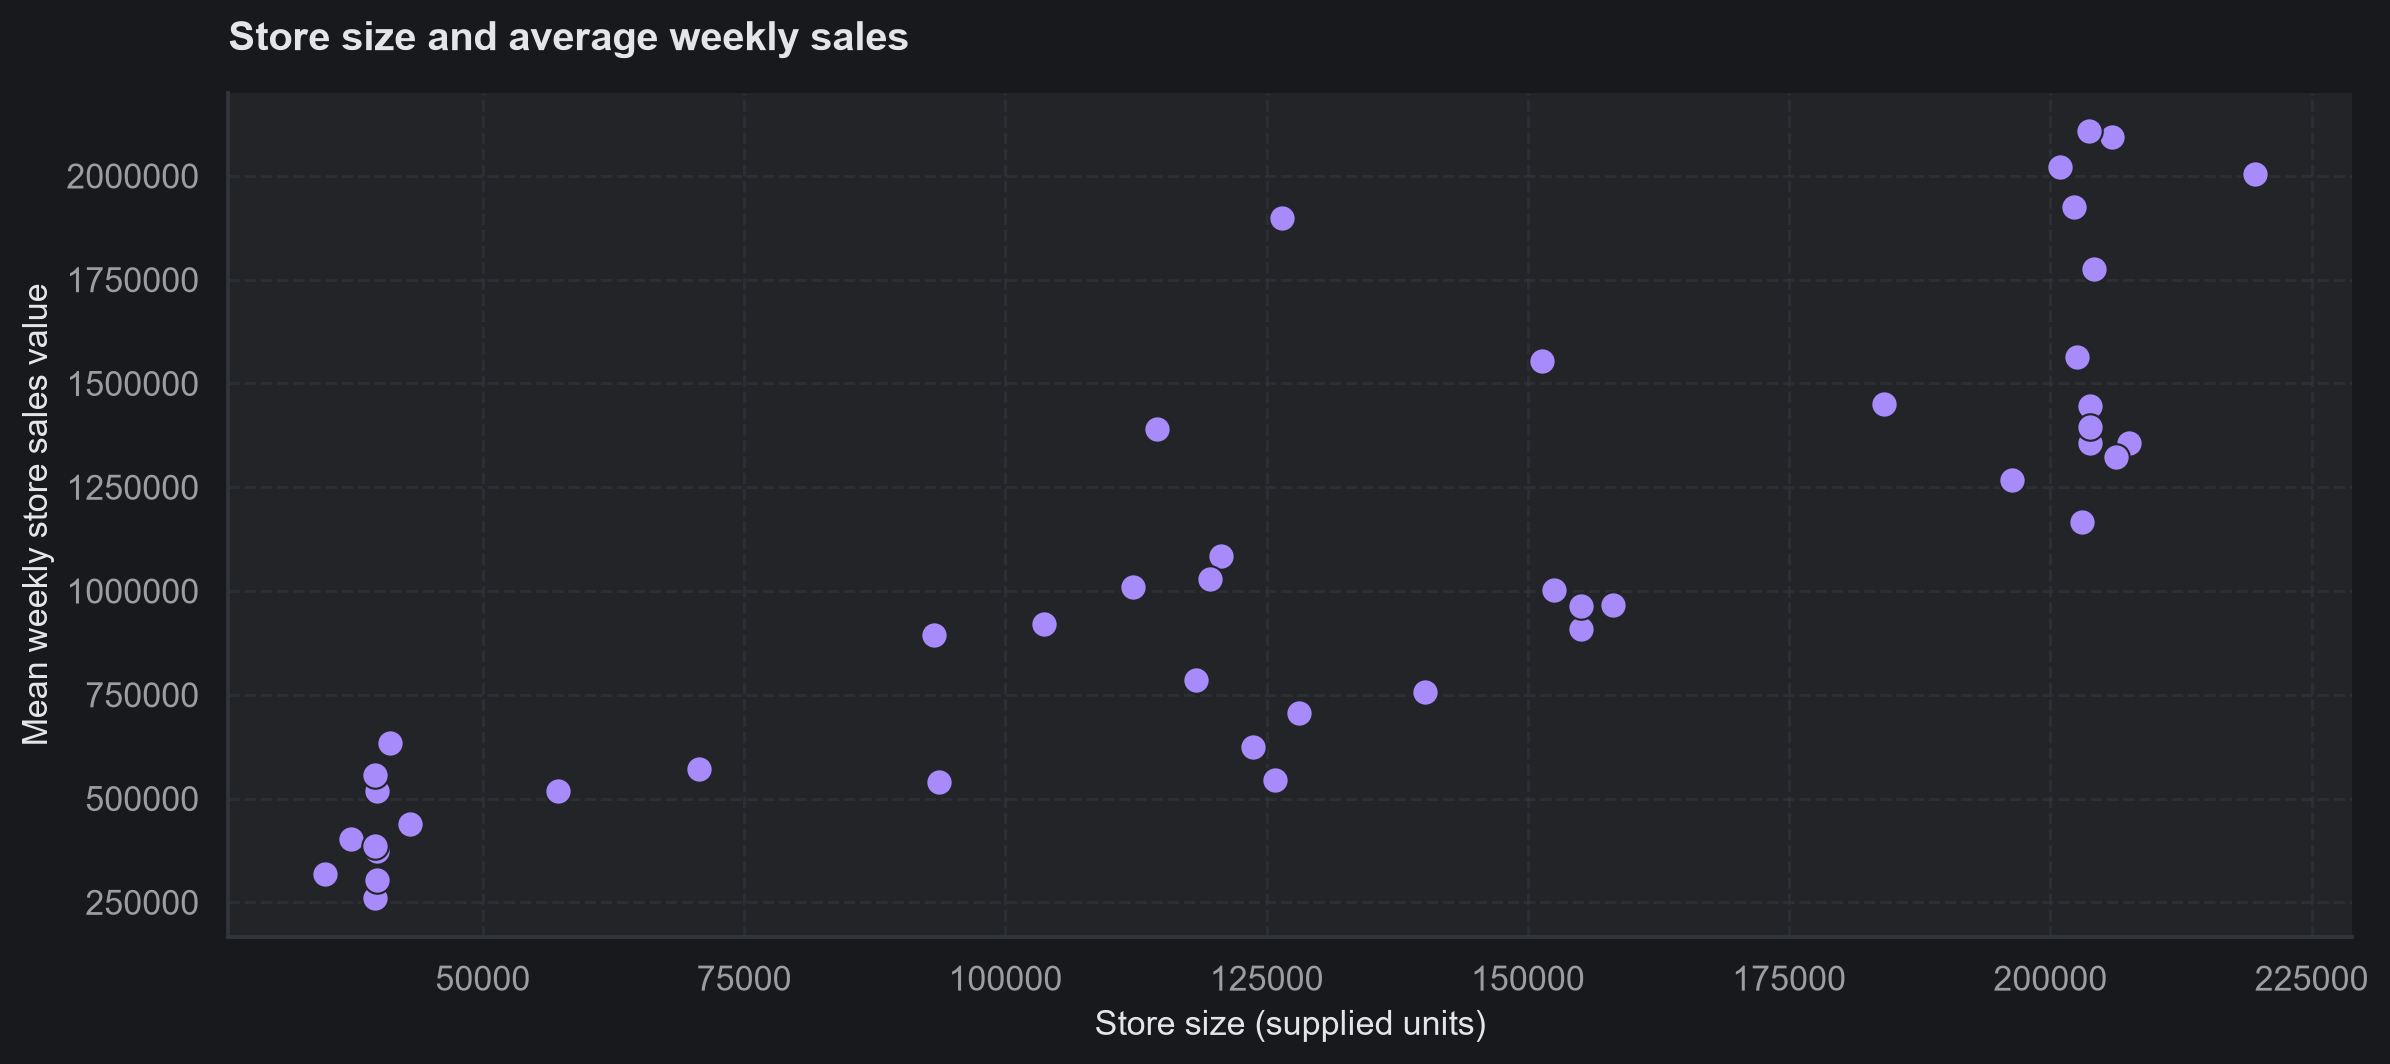

In [35]:
# One point per store avoids repeating its size for each week.
size_sales = store_week.groupby("Store").agg(Size=("Size", "first"), Sales=("Weekly_Sales", "mean"))
fig, ax = plt.subplots()
sns.scatterplot(data=size_sales, x="Size", y="Sales", color=PURPLE, s=75,
                edgecolor=CUSTOM_THEME["card"], linewidth=.7, ax=ax)
ax.ticklabel_format(style="plain", axis="both")
save_chart("10_size_sales", "Store size and average weekly sales",
           xlabel="Store size (supplied units)", ylabel="Mean weekly store sales value")

#### 1. Why did you pick the specific chart?

A scatter plot shows how two numerical store characteristics vary together without hiding individual observations. Each point represents one store, comparing its size with its average weekly sales.

#### 2. What is/are the insight(s) found from the chart?

The Pearson correlation is approximately 0.85, indicating a strong positive association between store size and average weekly sales. Larger stores generally sell more, but the relationship does not imply that stores of the same size perform identically. Sales scale should therefore be considered alongside other store characteristics.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

Size can help set more realistic sales expectations and make store comparisons fairer. It does not establish the financial return from expanding a store. Expansion decisions based only on this correlation could add space and operating costs without sufficient local demand.

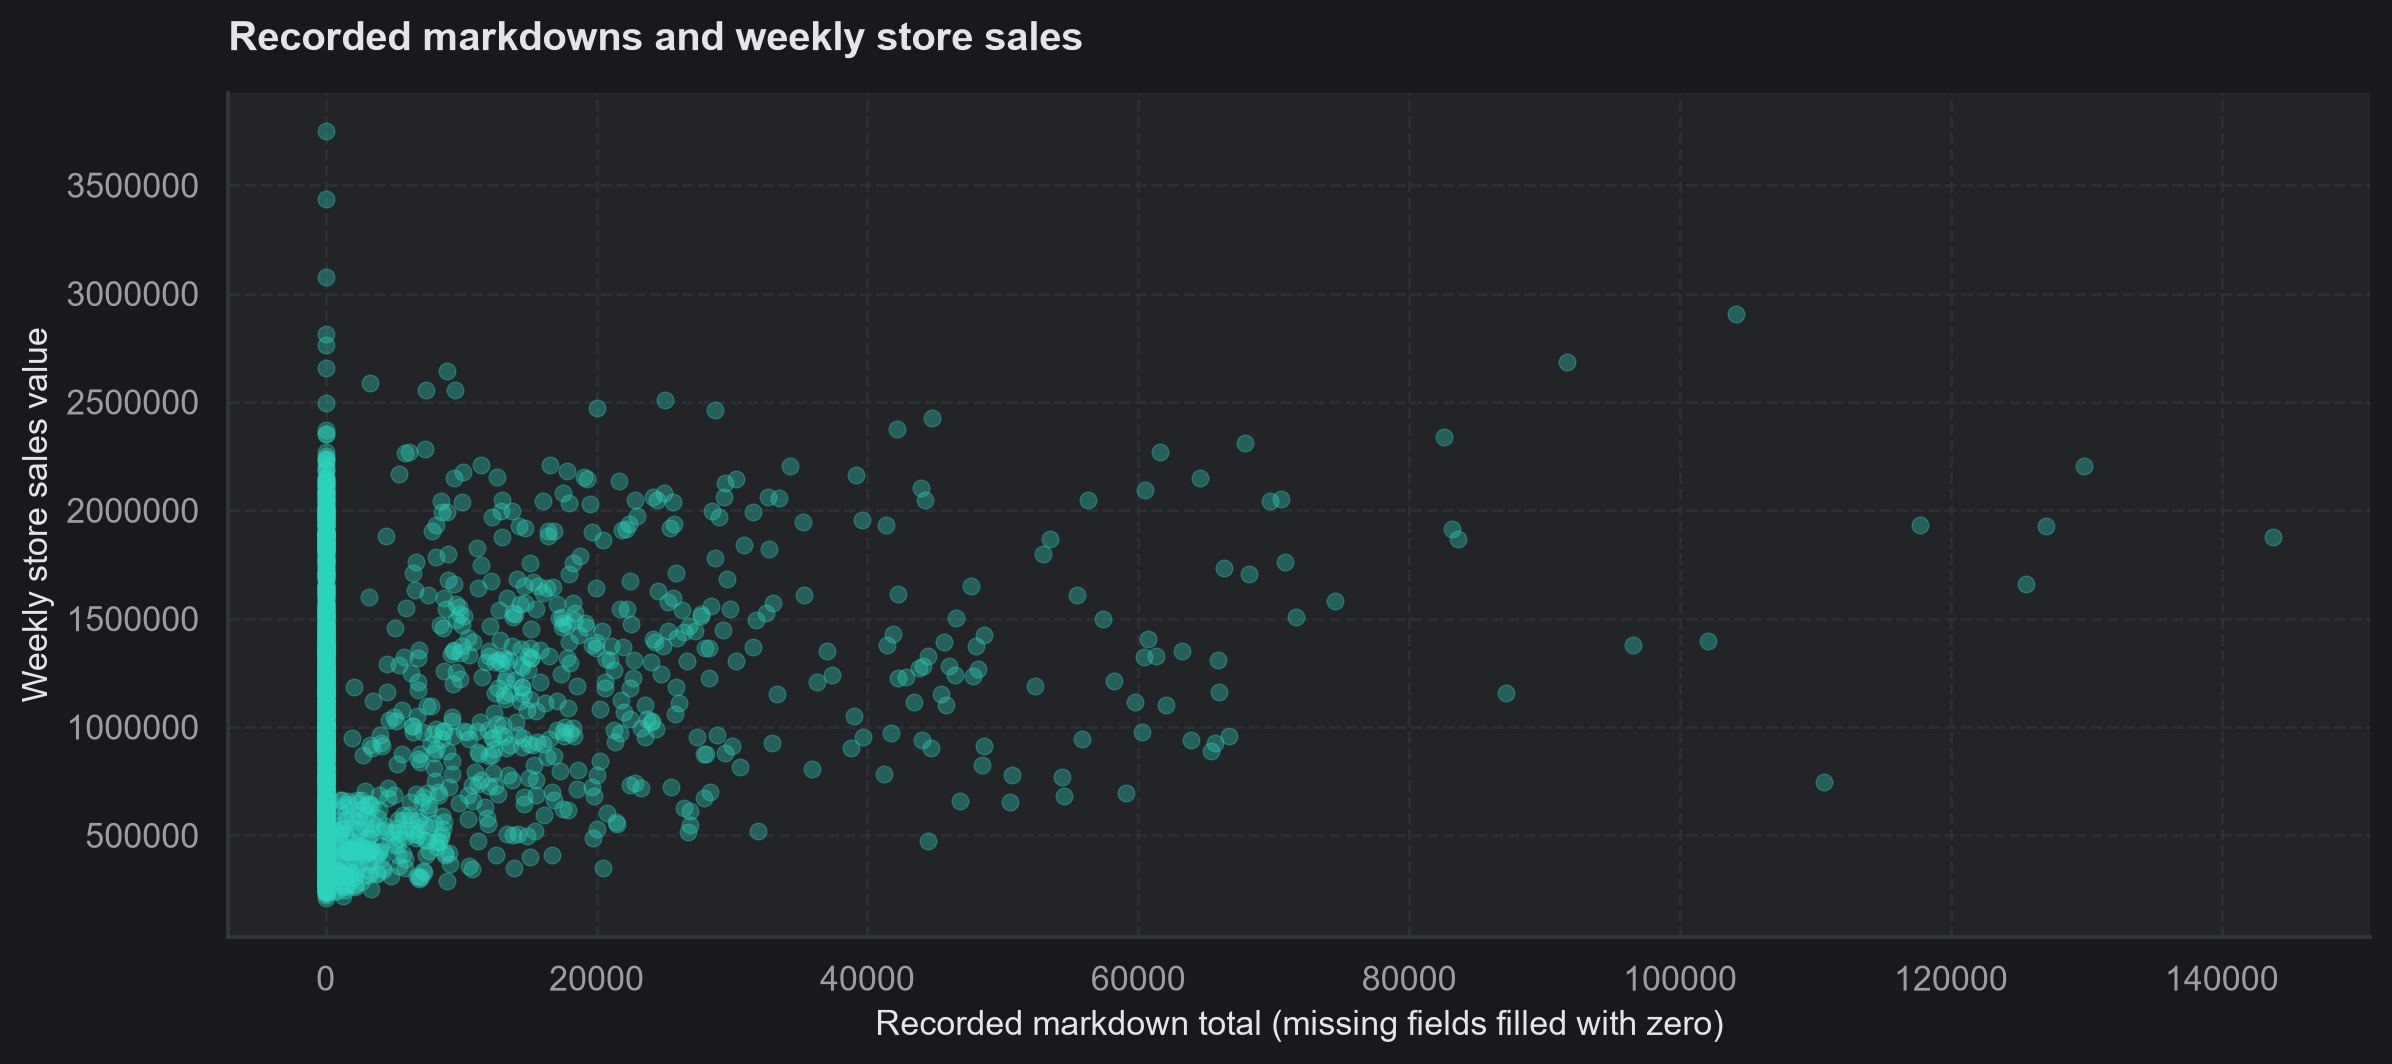

In [36]:
# Sample store-weeks for readability; use the full data for reported correlations.
promotion_sample = store_week.sample(min(2000, len(store_week)), random_state=SEED)
fig, ax = plt.subplots()
sns.scatterplot(data=promotion_sample, x="TotalMarkdown", y="Weekly_Sales",
                color=TEAL, alpha=.35, s=30, edgecolor=None, ax=ax)
ax.ticklabel_format(style="plain", axis="both")
save_chart("11_markdown_sales", "Recorded markdowns and weekly store sales",
           xlabel="Recorded markdown total (missing fields filled with zero)", ylabel="Weekly store sales value")

#### 1. Why did you pick the specific chart?

A scatter plot shows the relationship between recorded markdown totals and store-week sales while retaining the spread of individual observations. Using one point per store-week avoids counting the same promotion information repeatedly across departments.

#### 2. What is/are the insight(s) found from the chart?

The correlation is approximately 0.23, which indicates a weak positive association in the pooled data. Higher recorded markdowns do not correspond to one fixed sales outcome. Values recorded as zero also include missing markdown reports, which limits the interpretation of that part of the chart.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

The chart can identify promotion weeks worth reviewing and suggest questions for a campaign pilot. It cannot measure incremental sales or return on promotion spending because store scale, seasonality and reporting availability can affect both variables. Increasing discounts solely on this association could reduce margins without producing enough additional sales.

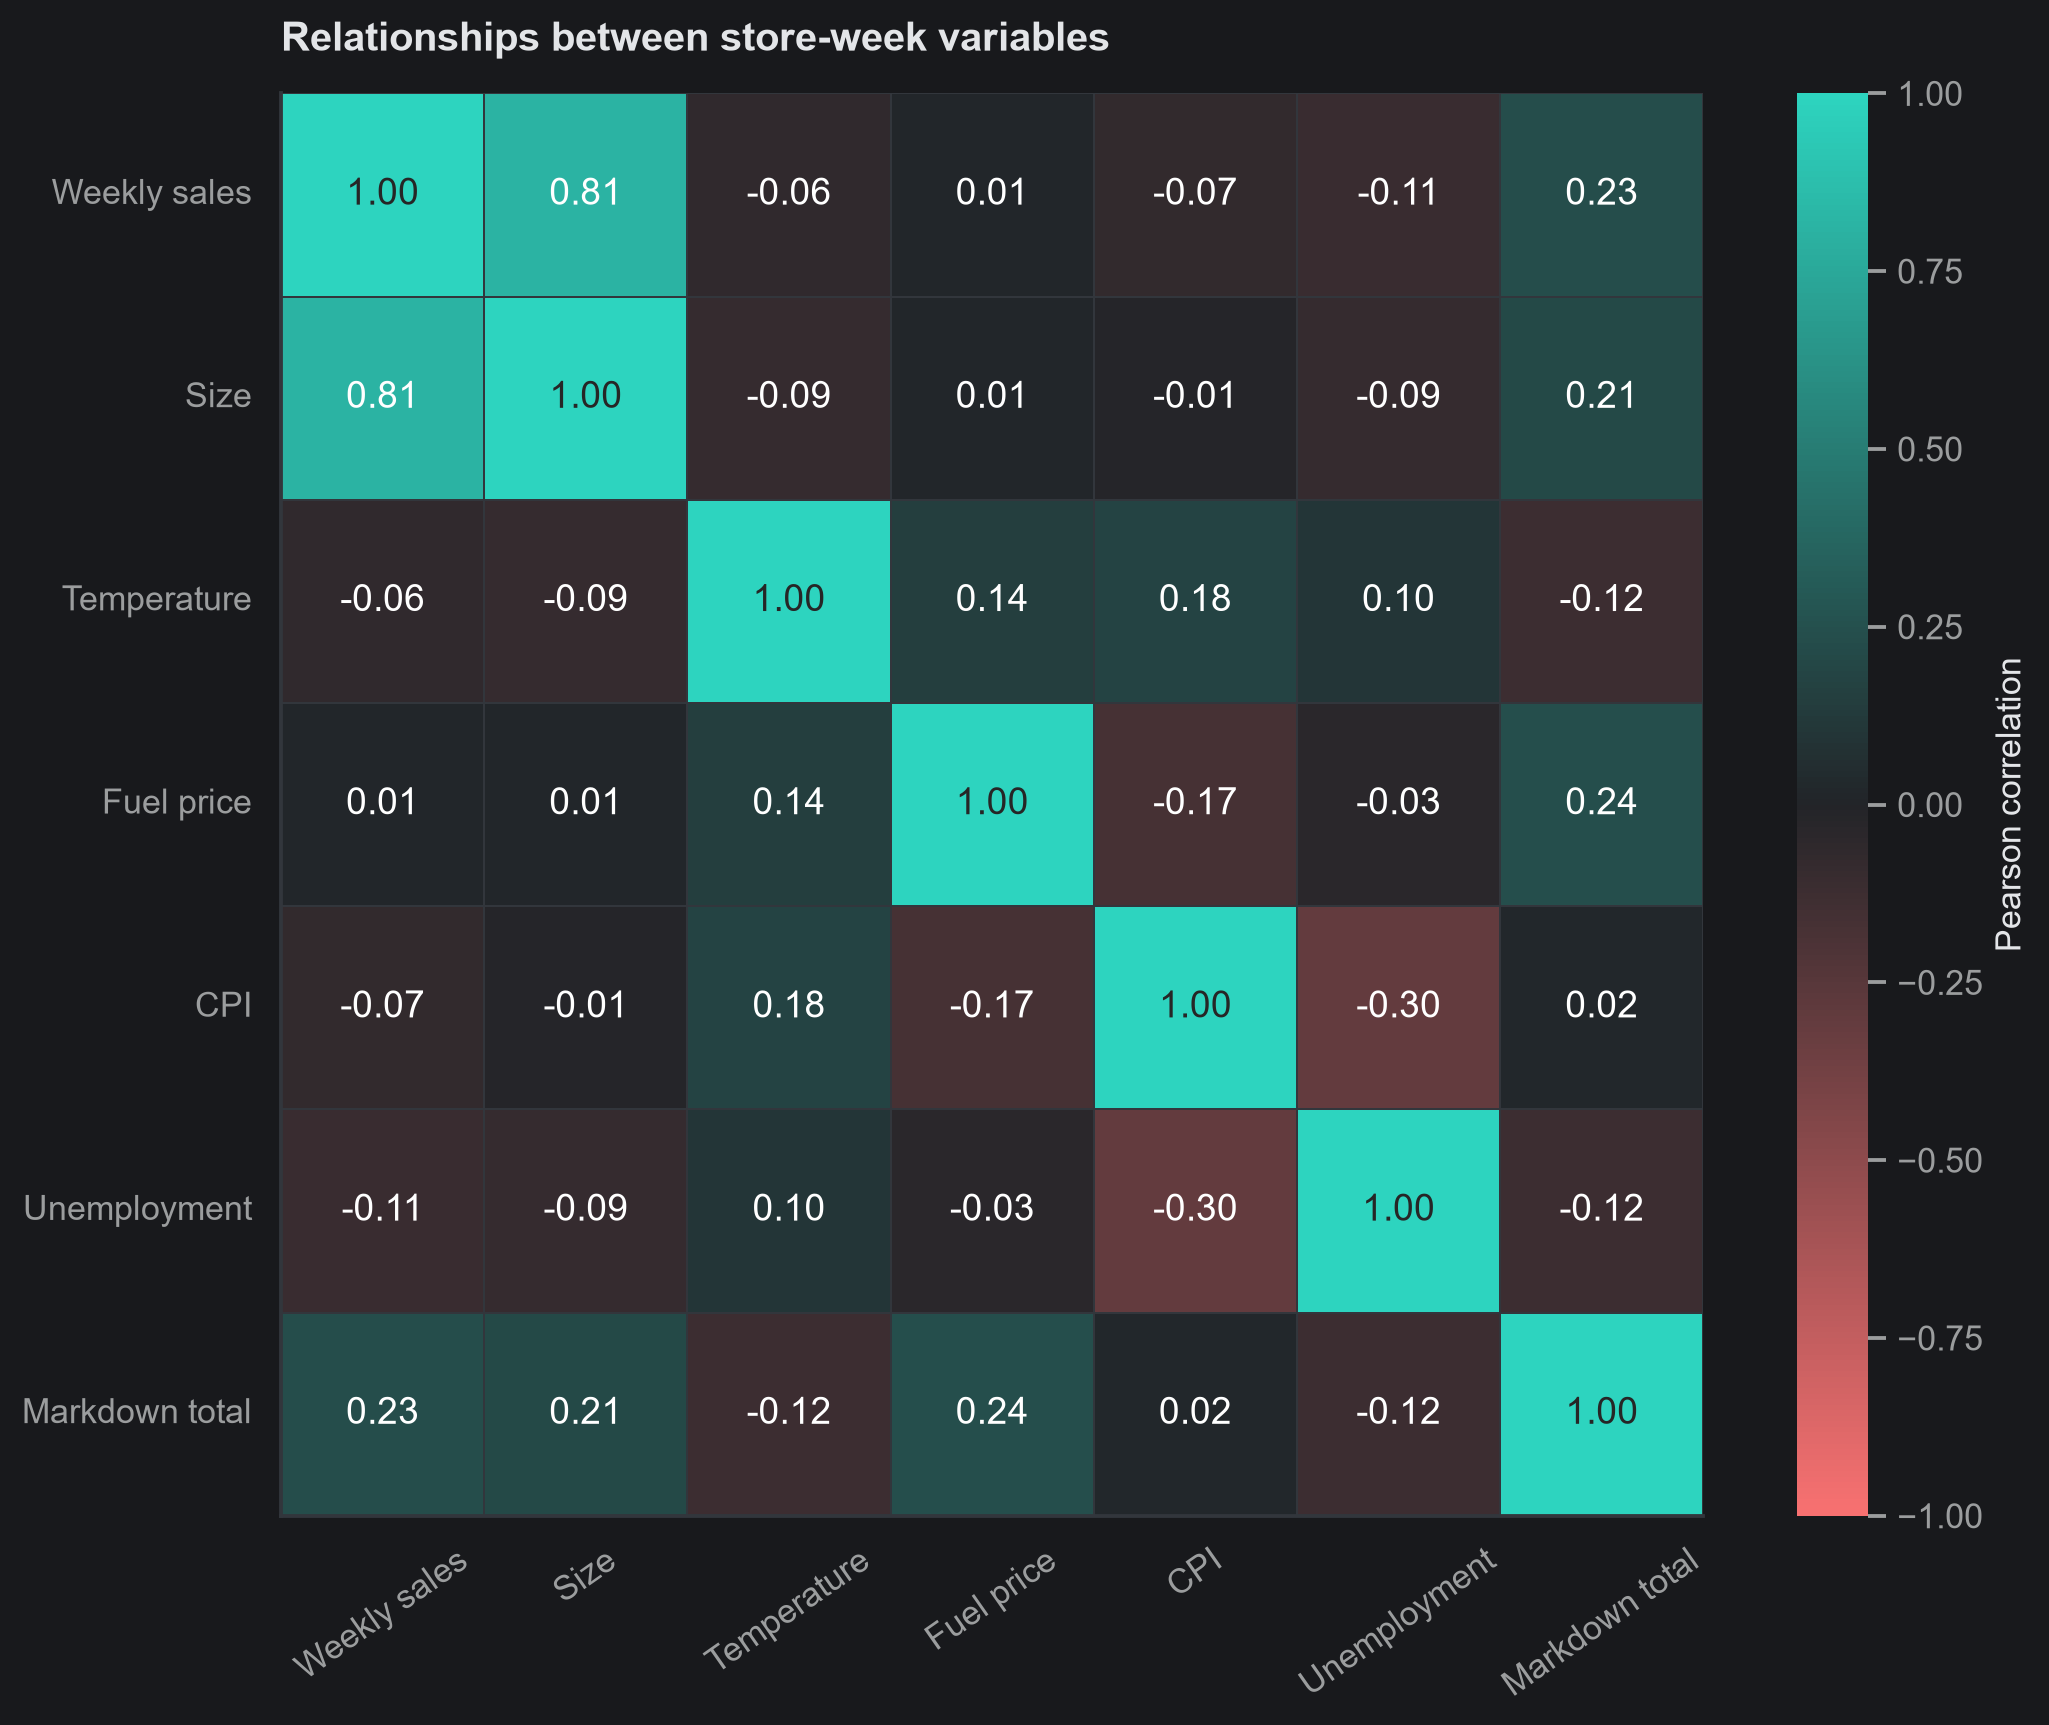

In [37]:
# Keep a full -1 to +1 scale so color strength is comparable across variables.
corr_columns = ["Weekly_Sales", "Size", "Temperature", "Fuel_Price", "CPI", "Unemployment", "TotalMarkdown"]
correlations = store_week[corr_columns].corr()
correlations = correlations.rename(index={"Weekly_Sales": "Weekly sales", "Fuel_Price": "Fuel price", "TotalMarkdown": "Markdown total"},
                                    columns={"Weekly_Sales": "Weekly sales", "Fuel_Price": "Fuel price", "TotalMarkdown": "Markdown total"})
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap=CORRELATION_CMAP, center=0,
            vmin=-1, vmax=1, linewidths=.6, linecolor=CUSTOM_THEME["grid"], square=True, cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.tick_params(axis="x", rotation=35)
save_chart("14_correlation", "Relationships between store-week variables")

#### 1. Why did you pick the specific chart?

A correlation heatmap summarizes several numerical relationships in one view. The colors show direction and strength, while the annotated coefficients allow a more precise comparison than color alone.

#### 2. What is/are the insight(s) found from the chart?

At the store-week level, the size-sales correlation is approximately 0.81, compared with 0.23 for recorded markdown totals. Store size therefore has the stronger pooled linear relationship with sales in this view. The size coefficient differs from the earlier 0.85 value because this heatmap uses store-weeks, while the earlier plot uses one average observation per store.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

The heatmap helps explain why store scale should be considered when comparing sales and promotion results. It can also flag related predictors that may share information. Treating each coefficient as an independent causal effect could produce misleading business recommendations, so model validation and store-level context are still needed.

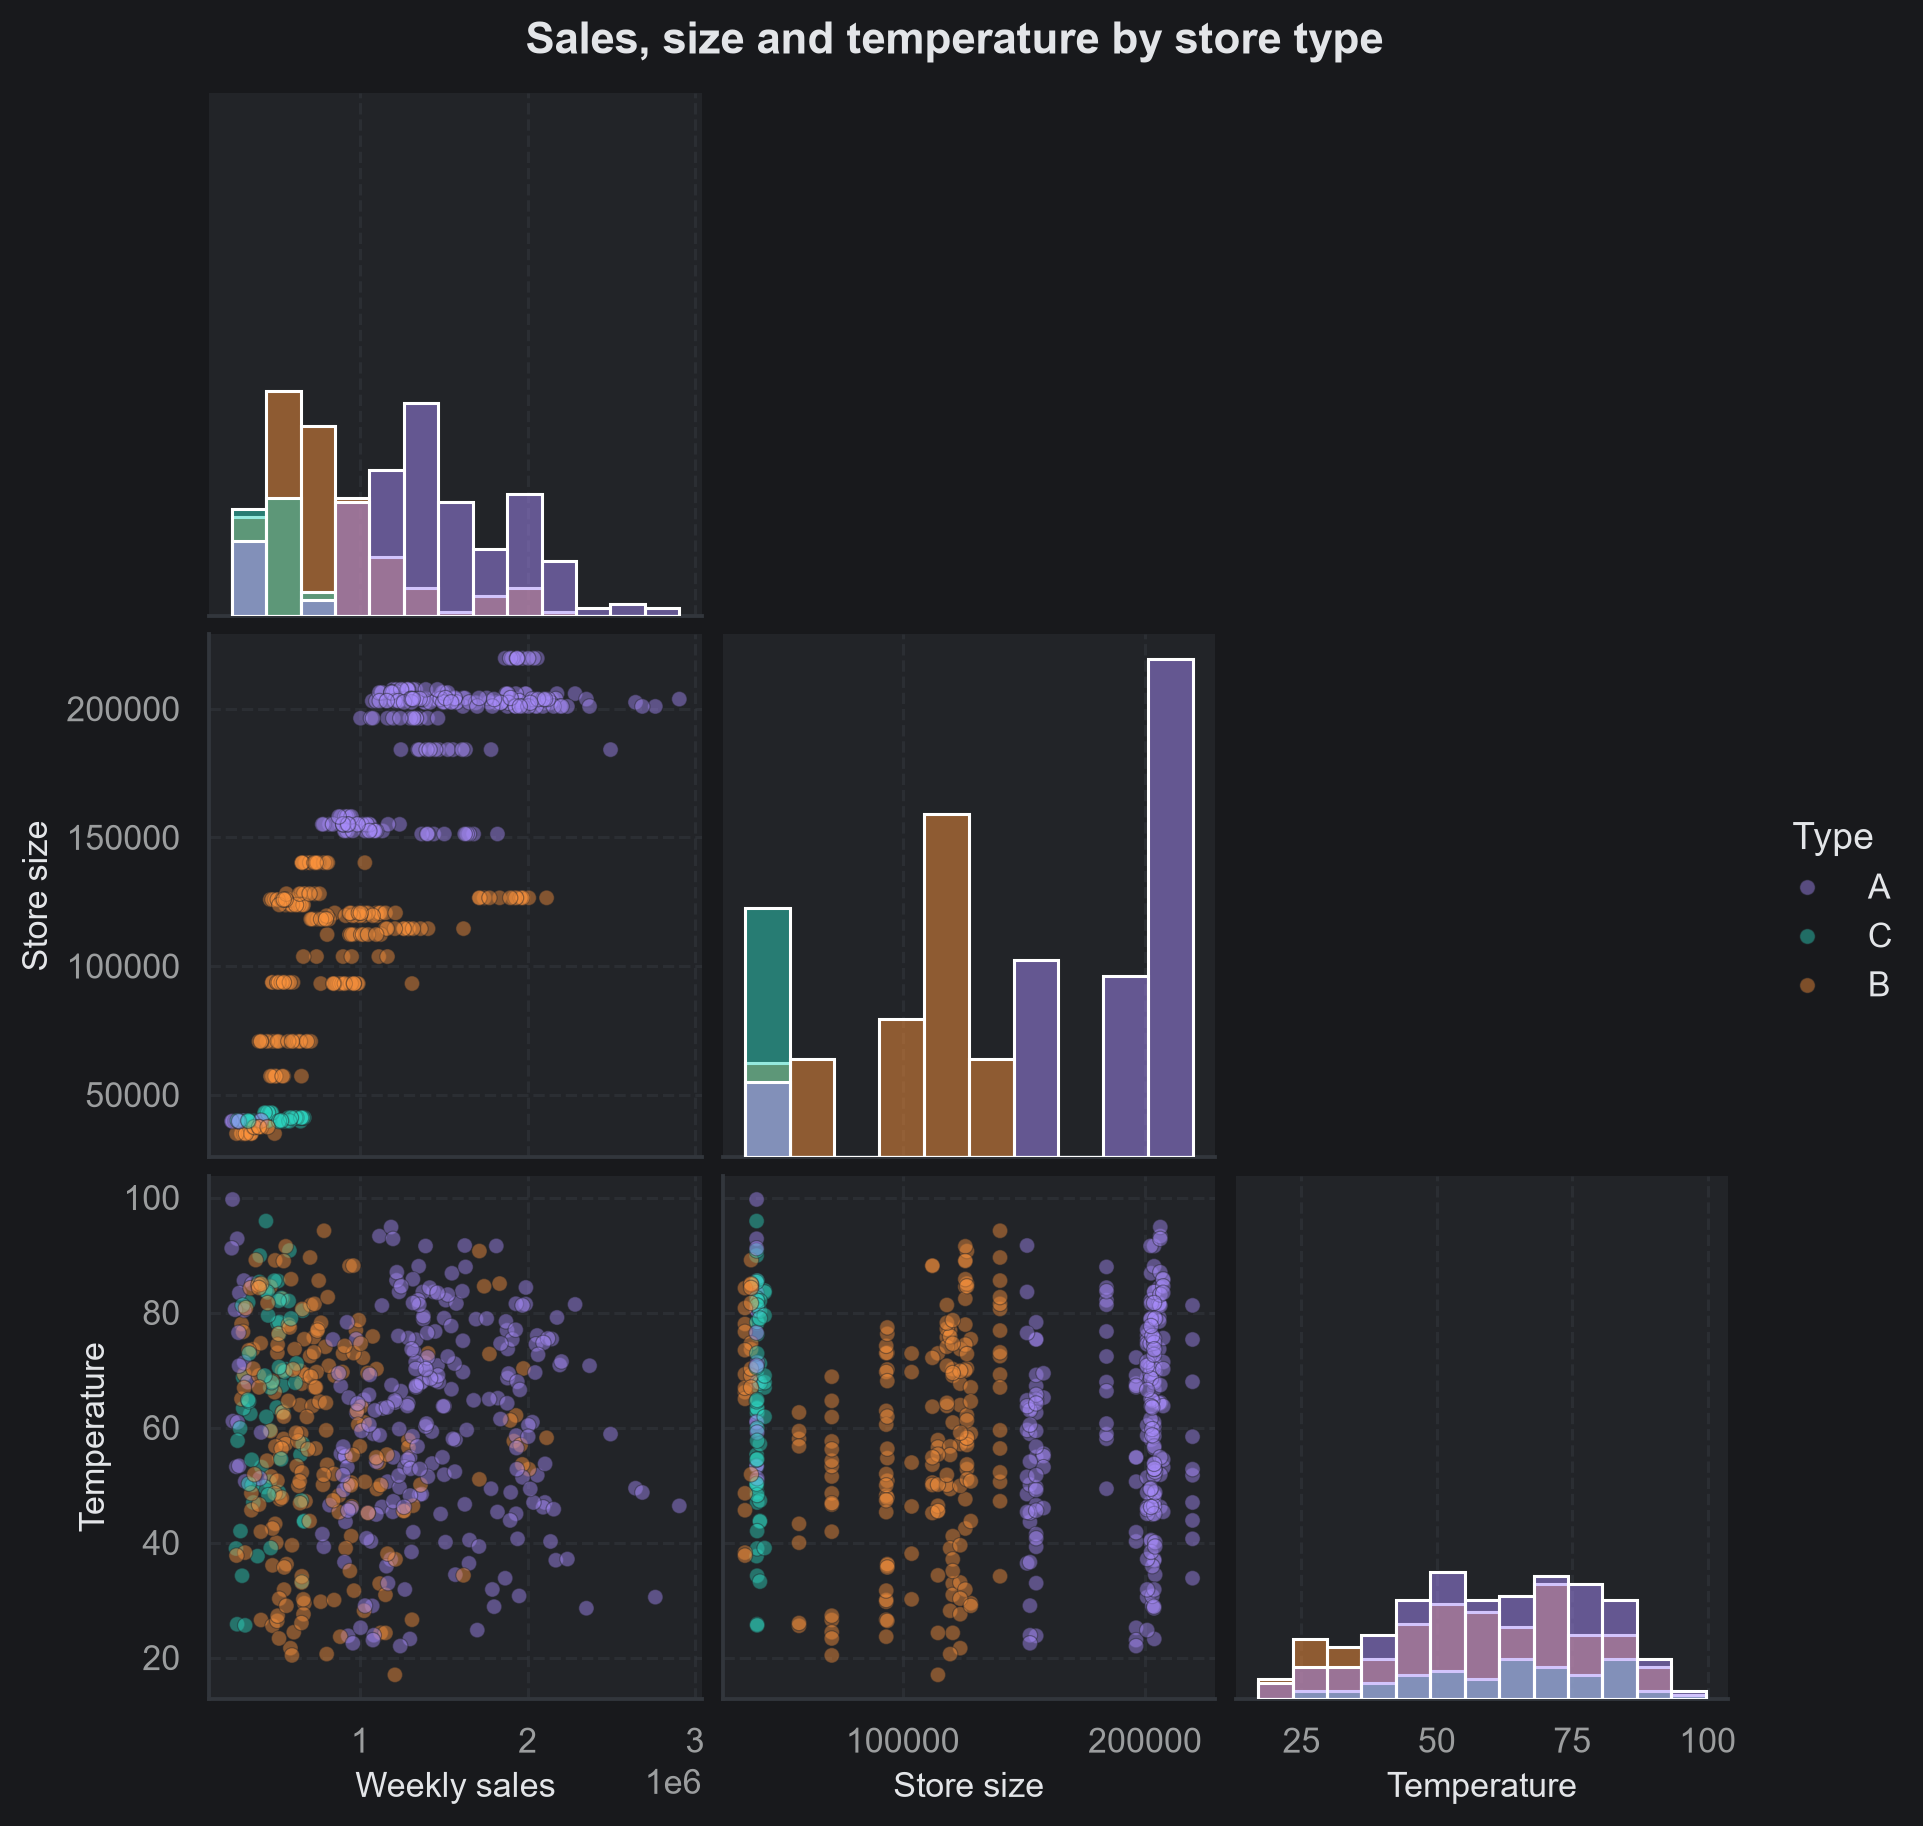

In [38]:
# Use the same seed so the displayed sample is reproducible.
pair_data = store_week.sample(min(500, len(store_week)), random_state=SEED)
pair_data = pair_data.rename(columns={"Weekly_Sales": "Weekly sales", "Size": "Store size"})
grid = sns.pairplot(pair_data, vars=["Weekly sales", "Store size", "Temperature"], hue="Type",
                    palette=[PURPLE, TEAL, ORANGE], corner=True, diag_kind="hist",
                    height=2.7, plot_kws={"alpha": .45, "s": 25, "edgecolor": CUSTOM_THEME["card"]})
grid.fig.suptitle("Sales, size and temperature by store type", y=1.02, fontweight="bold")
grid.fig.savefig(FIG / "15_pairplot.png", dpi=200, bbox_inches="tight", facecolor=CUSTOM_THEME["bg"])
plt.show()
plt.close(grid.fig)

#### 1. Why did you pick the specific chart?

A pair plot displays multiple numerical relationships and distributions together, with colors identifying store formats. It helps compare the sales-size relationship with temperature patterns while showing where formats overlap.

#### 2. What is/are the insight(s) found from the chart?

Type A has the highest average store-week sales in the full data, and the earlier store-level size-sales correlation is approximately 0.85. The sampled pair plot provides context for these findings and shows variation within formats. Because only 500 store-weeks are plotted, it should be read alongside the full-data summaries rather than used to estimate precise group differences.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

This view supports considering size and format together when developing store plans. It does not establish sharply separated business groups or a reliable rule for every individual store. The later segmentation profiles provide a more structured comparison; inflexible plans based only on the plotted colors could overlook stores that differ from their format's average.

## 5. Hypothesis Testing
Three exploratory questions use one summary per store (rather than pretending every department-week is independent). Use a two-sided 5% level with Bonferroni correction for three tests. Store summaries are still exposed to shared economic and holiday conditions, so p-values are exploratory evidence, not proof of causality.

1. Holiday versus nonholiday sales: H0 is no systematic paired difference in store mean weekly sales; H1 is a difference. Wilcoxon signed-rank compares paired store summaries.
2. Size and average sales: H0 is zero rank association; H1 is a nonzero association. Spearman correlation allows a monotonic relationship.
3. Recorded markdown availability: H0 is no paired difference between store means in positive-markdown and zero/unreported-markdown weeks; H1 is a difference. Wilcoxon compares stores with both kinds of weeks. This is confounded by timing and missing reports.

In [15]:
# Summarize each store before running the tests.
holiday_pairs = store_week.groupby(["Store", "IsHoliday"]).Weekly_Sales.mean().unstack().dropna()
holiday_test = stats.wilcoxon(holiday_pairs[True], holiday_pairs[False])
size_test = stats.spearmanr(size_sales.Size, size_sales.Sales)

promotion_weeks = store_week.copy()
promotion_weeks["RecordedPromotion"] = promotion_weeks["TotalMarkdown"] > 0
promo_pairs = promotion_weeks.groupby(
    ["Store", "RecordedPromotion"]
).Weekly_Sales.mean().unstack().dropna()
promotion_test = stats.wilcoxon(promo_pairs[True], promo_pairs[False])

hypotheses = pd.DataFrame([
    {"question": "Holiday paired difference", "stores": len(holiday_pairs),
     "statistic": holiday_test.statistic, "p_value": holiday_test.pvalue},
    {"question": "Size-sales Spearman", "stores": len(size_sales),
     "statistic": size_test.statistic, "p_value": size_test.pvalue},
    {"question": "Recorded-promotion paired difference", "stores": len(promo_pairs),
     "statistic": promotion_test.statistic, "p_value": promotion_test.pvalue}
])
# Bonferroni correction accounts for testing three questions.
hypotheses["adjusted_p"] = (hypotheses.p_value * 3).clip(upper=1)
hypotheses["decision_at_5pct"] = np.where(
    hypotheses.adjusted_p < .05, "Reject H0", "Do not reject H0"
)
display(hypotheses)

,question,stores,statistic,p_value,adjusted_p,decision_at_5pct
0,Holiday paired difference,45,24.000000,4.331469e-11,1.299441e-10,Reject H0
1,Size-sales Spearman,45,0.845244,2.815119e-13,8.445356e-13,Reject H0
2,Recorded-promotion paired difference,45,199.000000,1.912245e-04,5.736734e-04,Reject H0


## 6. Feature Engineering and Data Preprocessing
### Anomaly Detection and Handling
Fit store-department IQR bounds on training weeks only: flag values outside Q1 − 3×IQR to Q3 + 3×IQR. This conservative rule is a review aid, not a labeled classifier. Save bounds as the reusable anomaly model. Compare anomalies by holiday flag and inspect the largest positive deviations.

For time-based anomalies, compare each series to the median and standard deviation of the preceding eight observed weeks, shifted by one row. The first four observations have insufficient history. A separate chain-level view compares each week to its preceding eight weeks. These are sequential monitoring rules; they do not use future observations. Rows may span gaps, so eight observations need not mean eight calendar weeks.

Keep original targets in the primary forecast. A small validation experiment later tests training-only clipping. Do not remove valid holiday spikes merely because they are unusual. Without verified anomaly labels, precision/recall cannot be honestly reported.

,IQR_anomaly,Time_anomaly
IsHoliday,,
False,1.523823,5.826353
True,3.941202,11.243721


,Store,Dept,Date,Weekly_Sales,IsHoliday,TotalMarkdown,upper
278488,35,72,2011-11-25,649770.18,True,66304.31,179768.080
125344,35,72,2010-11-26,627962.93,True,0.00,179768.080
123652,10,72,2010-11-26,693099.36,True,0.00,280316.075
276751,10,72,2011-11-25,630999.19,True,143223.31,280316.075
135402,10,7,2010-12-24,406988.63,False,0.00,92041.360
124827,27,72,2010-11-26,420586.57,True,0.00,129853.920
123930,14,72,2010-11-26,474330.10,True,0.00,186547.675
124479,22,72,2010-11-26,393705.20,True,0.00,135329.975
278702,39,72,2011-11-25,351553.98,True,82596.35,95046.890
276895,12,72,2011-11-25,360140.66,True,70708.06,109801.890


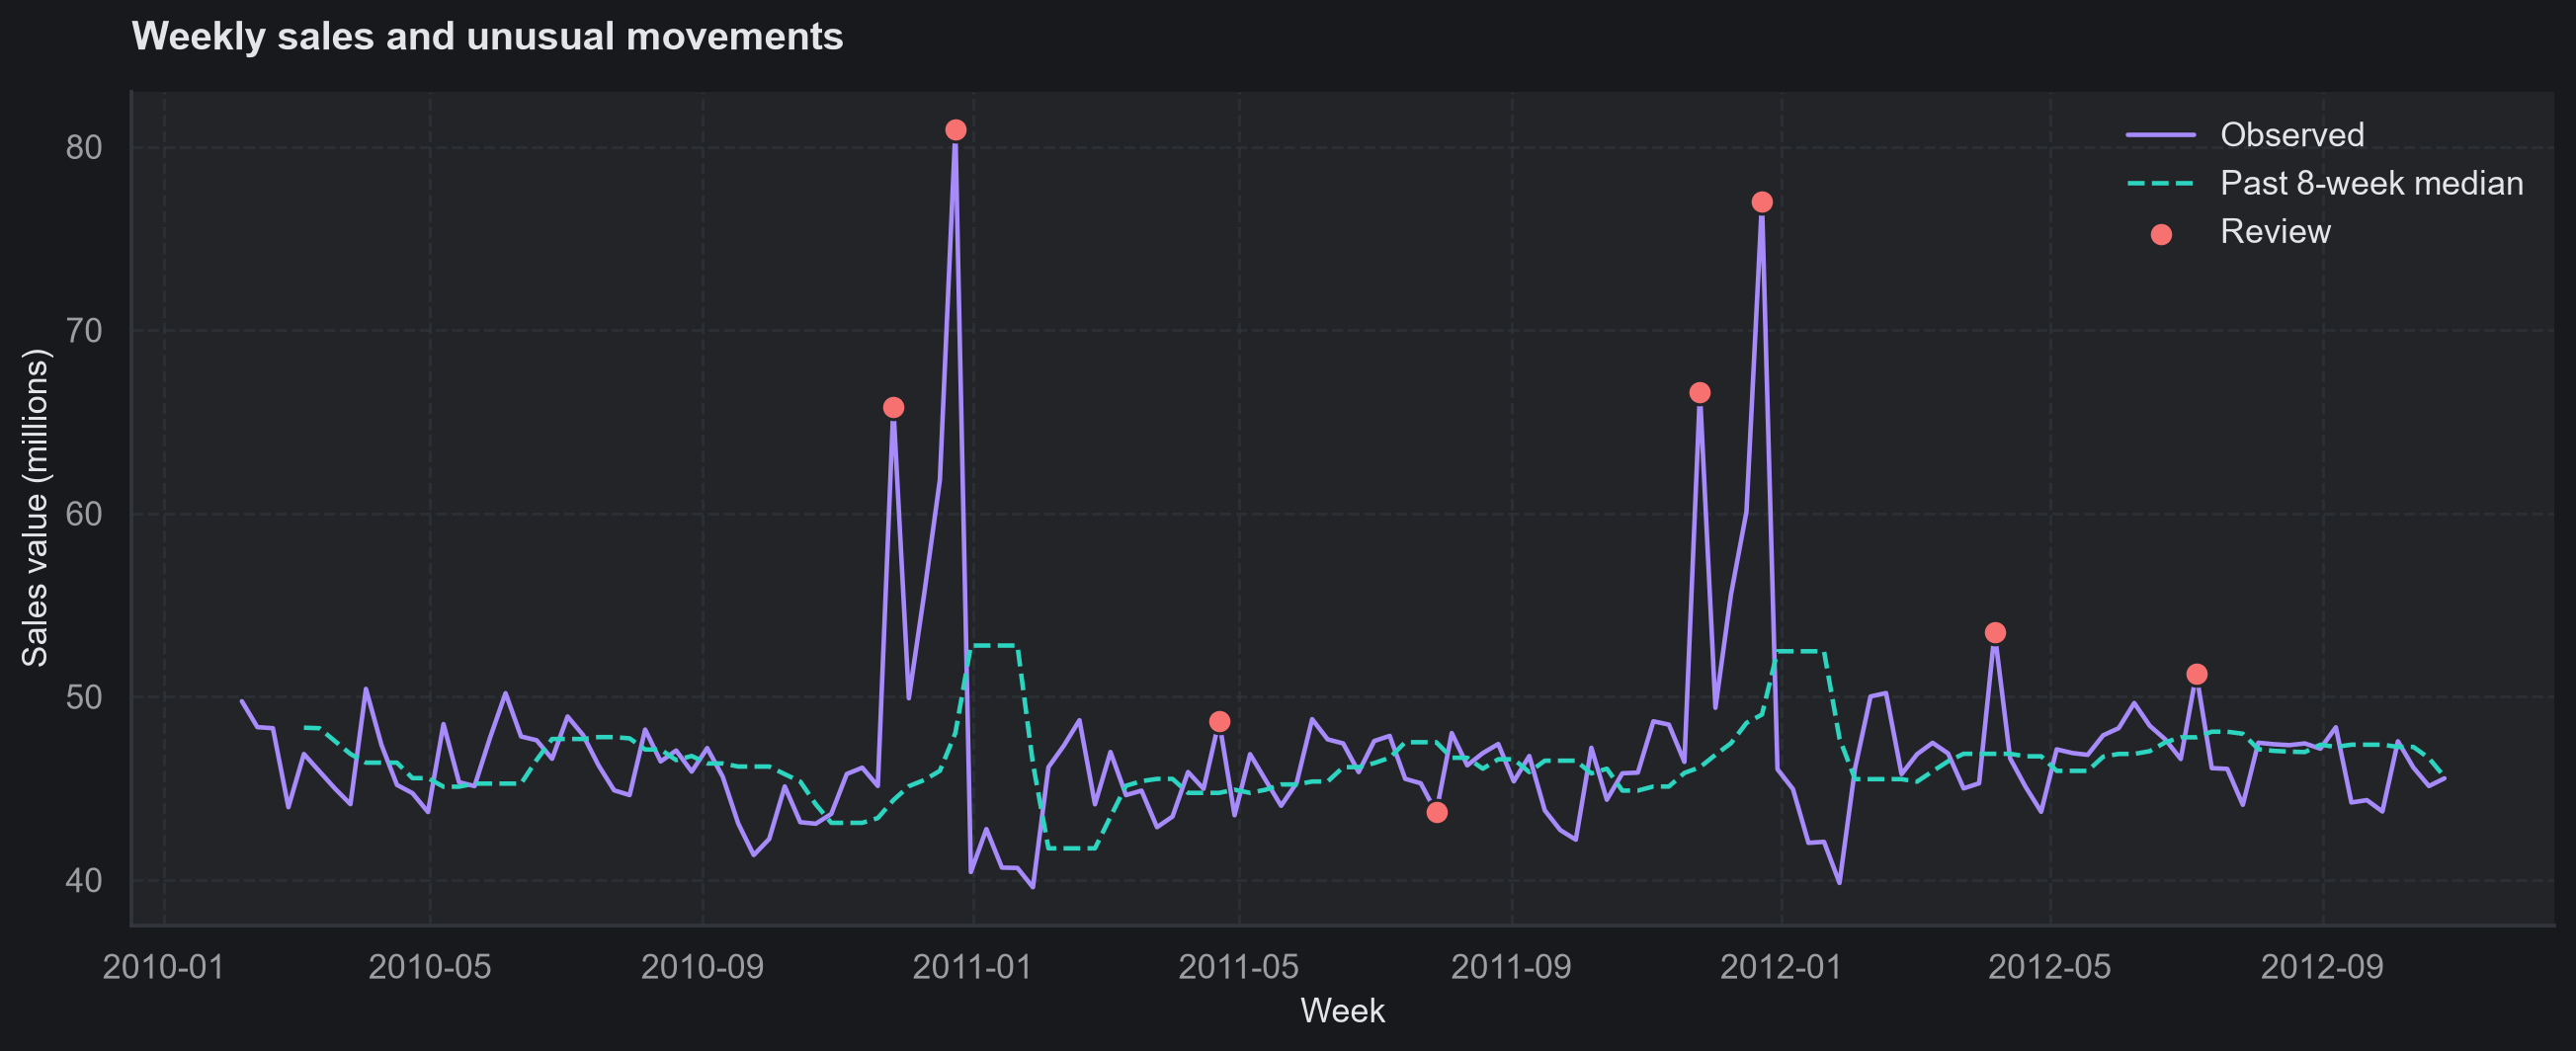

In [39]:
bounds = train.groupby(["Store", "Dept"]).Weekly_Sales.quantile([.25, .75]).unstack()
bounds.columns = ["q1", "q3"]
bounds["lower"] = bounds.q1 - 3 * (bounds.q3 - bounds.q1)
bounds["upper"] = bounds.q3 + 3 * (bounds.q3 - bounds.q1)
audit = df.join(bounds[["lower", "upper"]], on=["Store", "Dept"])
audit["IQR_anomaly"] = (audit.Weekly_Sales < audit.lower) | (audit.Weekly_Sales > audit.upper)
audit["excess"] = audit.Weekly_Sales - audit.upper
audit = audit.sort_values(["Store", "Dept", "Date"])
series = audit.groupby(["Store", "Dept"]).Weekly_Sales
audit["past_median"] = series.transform(lambda x: x.shift(1).rolling(8, min_periods=4).median())
audit["past_std"] = series.transform(lambda x: x.shift(1).rolling(8, min_periods=4).std())
audit["Time_anomaly"] = (audit.Weekly_Sales - audit.past_median).abs() > 3 * audit.past_std
display(audit.groupby("IsHoliday")[["IQR_anomaly", "Time_anomaly"]].mean().mul(100))
display(audit.nlargest(10, "excess")[["Store", "Dept", "Date", "Weekly_Sales", "IsHoliday", "TotalMarkdown", "upper"]])
joblib.dump({"bounds": bounds, "multiplier": 3, "fit_end": train.Date.max()}, MODEL / "anomaly_model.joblib")
past_center = weekly.shift(1).rolling(8, min_periods=4).median()
past_scale = weekly.shift(1).rolling(8, min_periods=4).std()
time_flags = (weekly - past_center).abs() > 3 * past_scale
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(x=weekly.index, y=weekly.to_numpy() / 1e6, color=PURPLE, label="Observed", ax=ax)
sns.lineplot(x=past_center.index, y=past_center.to_numpy() / 1e6, color=TEAL,
             linestyle="--", label="Past 8-week median", ax=ax)
ax.scatter(weekly.index[time_flags], weekly[time_flags] / 1e6, color=CORAL,
           s=65, edgecolor=CUSTOM_THEME["card"], zorder=3, label="Review")
ax.legend(frameon=False)
save_chart("16_time_anomalies", "Weekly sales and unusual movements", xlabel="Week", ylabel="Sales value (millions)")

#### 1. Why did you pick the specific chart?

A time-ordered line chart places flagged weeks next to observed chain sales and the median of preceding weeks. This makes the size and timing of unusual movements easier to interpret than a list of flagged dates alone.

#### 2. What is/are the insight(s) found from the chart?

Eight chain-level weeks exceed the trailing three-standard-deviation rule. These are unusual relative to recent history, rather than confirmed reporting errors. The reference uses past weeks only, so a sudden legitimate seasonal peak can also be flagged; these eight chain-level flags are separate from the department-level flag counts.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

The chart helps managers focus investigations on specific dates and check holidays, promotions, returns and data feeds. Verified errors can then be corrected, while valid peaks remain available for forecasting. Automatically deleting every flag could remove important seasonal demand information and lead to underplanning.

### Missing Values, Encoding, Scaling and Selection
Markdowns are zero-filled as a working assumption, with `MarkdownMissing` marking unknown information. Other numeric predictors use training medians. Store, department and format use one-hot encoding, including safe handling of unseen categories. Tree models do not need scaling; K-means does.

Use calendar, store and external factors selected by business relevance. No current-week sales totals, anomaly flags derived from the target, or future target values are predictors. No NLP, class balancing, dimensionality reduction or log-target transformation is needed. Negative sales remain possible returns.

The external-factor models are conditional forecasts: temperature, economics and actual markdown values are observed inputs in this historical evaluation. Operational forecasts require planned promotions and forecasts/scenarios for unknown conditions. A calendar/store-only comparison below tests performance without these observed external inputs.

In [17]:
category_cols = ["Store", "Dept", "Type"]
base_numeric = ["Size", "IsHoliday", "Year", "Month", "Week", "Trend"]
external_cols = ["Temperature", "Fuel_Price", "CPI", "Unemployment",
                 *markdown_cols, "TotalMarkdown", "MarkdownMissing"]
numeric_cols = base_numeric + external_cols
predictor_cols = category_cols + numeric_cols

def make_pipeline(estimator, use_external=True):
    # Every fold fits its own imputer and encoder.
    if use_external:
        numeric = numeric_cols
    else:
        numeric = base_numeric
    preprocessing = ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median"), numeric),
        ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), category_cols)
    ])
    return Pipeline([("preprocessing", preprocessing), ("model", estimator)])

def metrics(actual, predicted, holidays):
    weights = np.where(np.asarray(holidays), 5, 1)
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
            "Holiday_WMAE": np.average(np.abs(np.asarray(actual) - predicted), weights=weights)}

def mean_forecast(history, future):
    # Calculate one average for each store-department pair.
    means = history.groupby(["Store", "Dept"], as_index=False)["Weekly_Sales"].mean()
    means = means.rename(columns={"Weekly_Sales": "MeanSales"})
    # A left join keeps the prediction rows in the same order as the inputs.
    predictions = future[["Store", "Dept"]].merge(means, on=["Store", "Dept"], how="left")
    # New pairs use the overall historical average.
    return predictions["MeanSales"].fillna(history["Weekly_Sales"].mean()).to_numpy()

display(split_summary)
print("Predictors:", predictor_cols)

,split,rows,weeks,start,end
0,train,350595,119,2010-02-05,2012-05-11
1,validation,47246,16,2012-05-18,2012-08-31
2,test,23729,8,2012-09-07,2012-10-26


Predictors: ['Store', 'Dept', 'Type', 'Size', 'IsHoliday', 'Year', 'Month', 'Week', 'Trend', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4', 'MarkDown5', 'TotalMarkdown', 'MarkdownMissing']


### Store Segmentation and Quality Evaluation
Aggregate training data to one row per store. Use average weekly store sales, sales variability, size, recorded markdowns, CPI and unemployment. Impute and standardize before K-means so measurement units do not dominate distances. Compare k=2–5 using silhouette (higher means better separation); inertia describes within-cluster compactness and generally falls as k increases. With only 45 stores, clusters are exploratory and may mostly reflect scale.

,k,silhouette,inertia
0,2,0.345427,153.159952
1,3,0.249575,122.245922
2,4,0.303534,95.265551
3,5,0.310341,79.072590


,Stores,MeanSales,SalesStd,Size,MeanMarkdown,CPI,Unemployment
Segment,,,,,,,
0,23,6.065883e+05,81622.932682,85508.956522,2710.965038,174.688619,8.043099
1,22,1.509661e+06,222148.108094,177101.636364,7091.887708,166.537303,8.265055


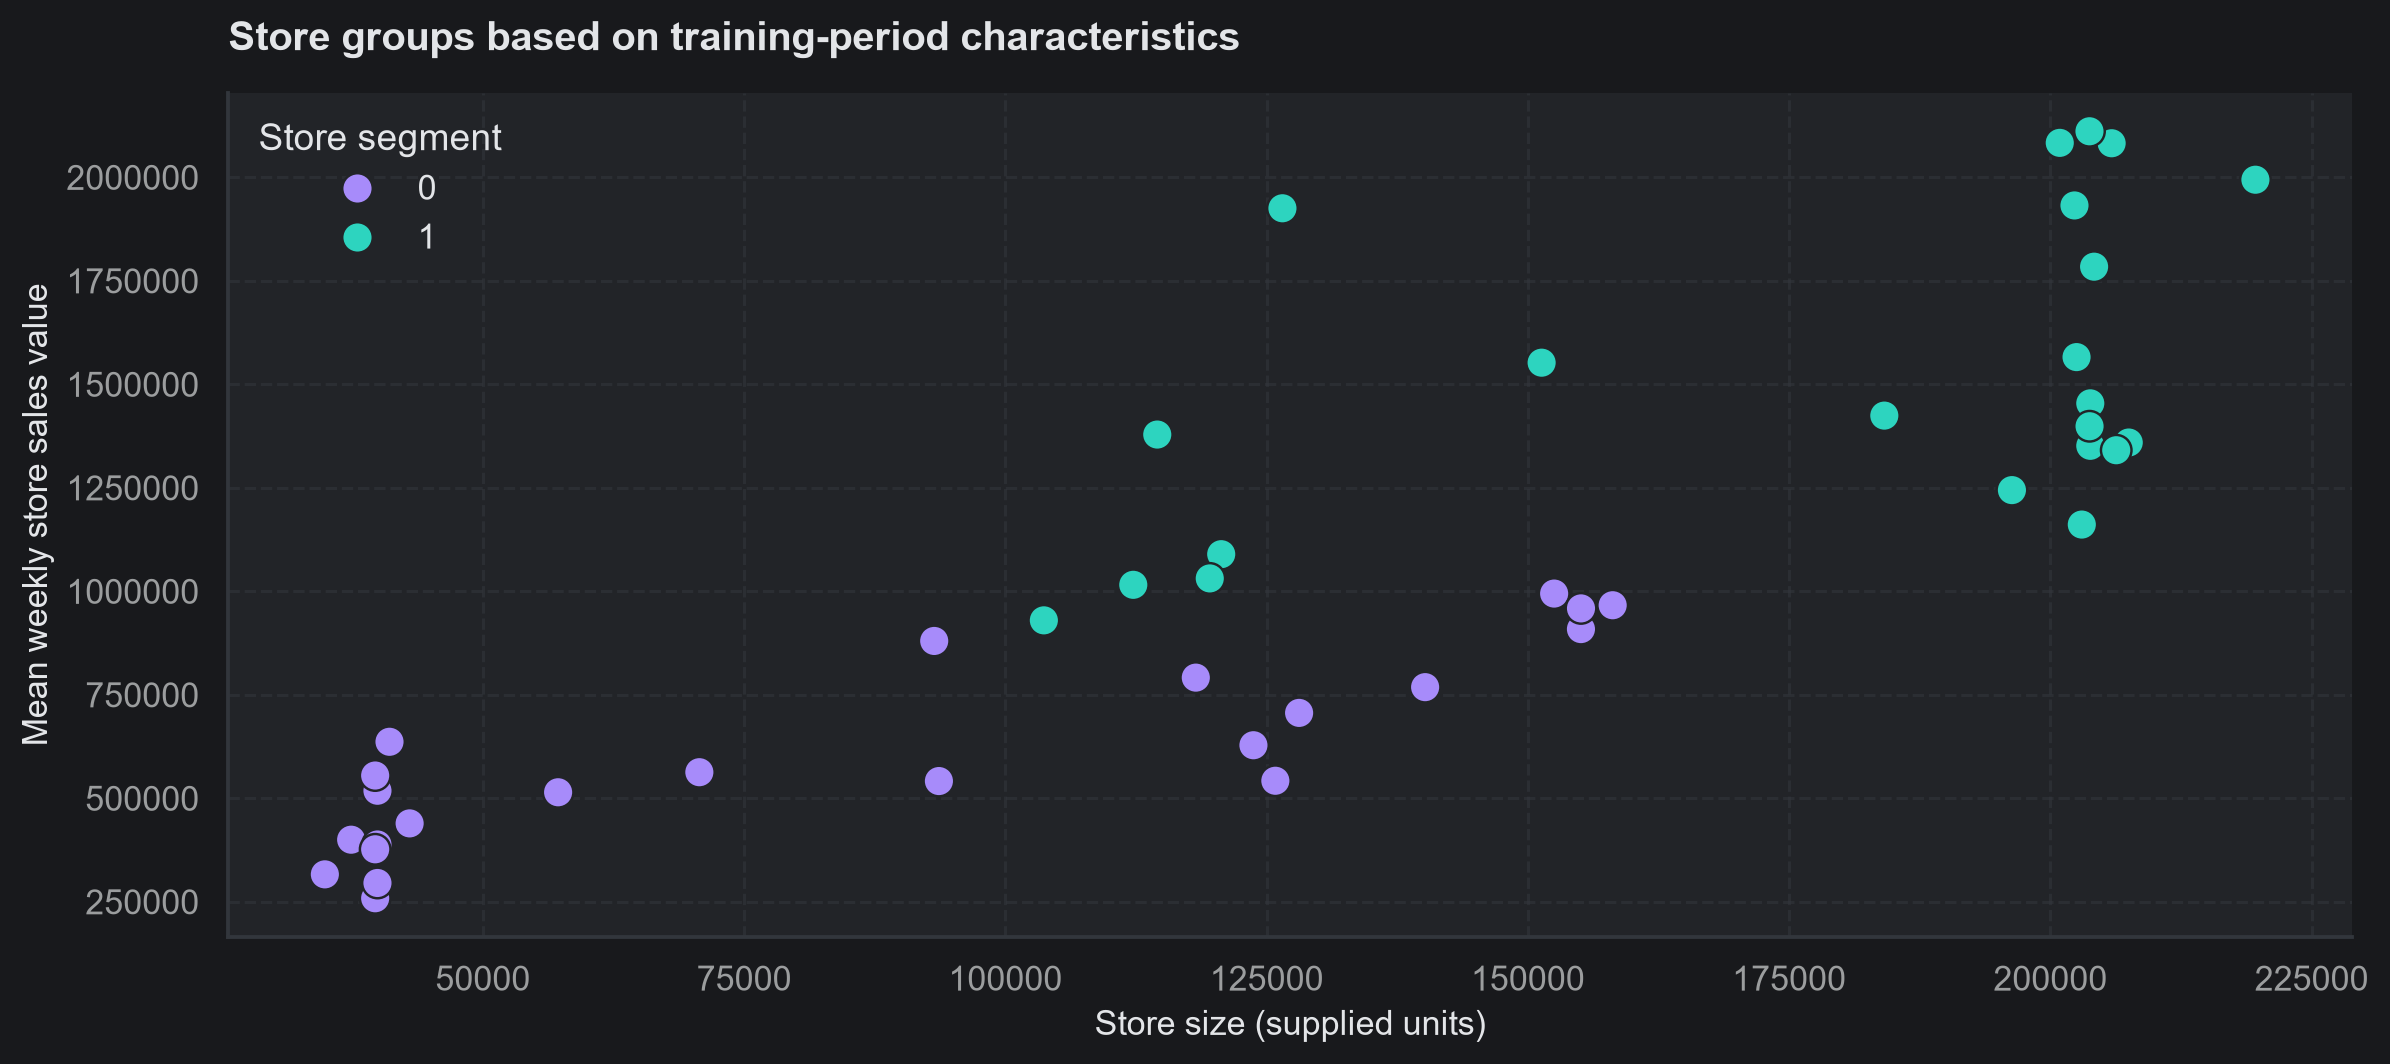

In [40]:
train_store_week = store_week[store_week.Date < val_start]
store_profiles = train_store_week.groupby("Store").agg(
    MeanSales=("Weekly_Sales", "mean"), SalesStd=("Weekly_Sales", "std"),
    Size=("Size", "first"), MeanMarkdown=("TotalMarkdown", "mean"),
    CPI=("CPI", "mean"), Unemployment=("Unemployment", "mean"))
segment_features = store_profiles.columns.tolist()
segment_preprocess = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
scaled_stores = segment_preprocess.fit_transform(store_profiles)
cluster_results = []
cluster_models = {}
for k in range(2, 6):
    clustering = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = clustering.fit_predict(scaled_stores)
    cluster_models[k] = clustering
    cluster_results.append([k, silhouette_score(scaled_stores, labels), clustering.inertia_])
cluster_scores = pd.DataFrame(cluster_results, columns=["k", "silhouette", "inertia"])
best_k = int(cluster_scores.loc[cluster_scores.silhouette.idxmax(), "k"])
store_profiles["Segment"] = cluster_models[best_k].labels_
segment_summary = store_profiles.groupby("Segment")[segment_features].mean()
segment_summary.insert(0, "Stores", store_profiles.groupby("Segment").size())
display(cluster_scores)
display(segment_summary)
joblib.dump({"preprocessing": segment_preprocess, "model": cluster_models[best_k],
             "columns": segment_features}, MODEL / "store_segmentation.joblib")
fig, ax = plt.subplots()
sns.scatterplot(data=store_profiles, x="Size", y="MeanSales", hue="Segment",
                palette={0: PURPLE, 1: TEAL}, s=100, edgecolor=CUSTOM_THEME["card"], ax=ax)
ax.ticklabel_format(style="plain", axis="both")
ax.legend(title="Store segment", frameon=False)
save_chart("17_store_segments", "Store groups based on training-period characteristics",
           xlabel="Store size (supplied units)", ylabel="Mean weekly store sales value")

#### 1. Why did you pick the specific chart?

A scatter plot of store size against mean sales makes the scale of the store segments easy to interpret. Coloring the points by cluster connects the statistical grouping with two familiar business characteristics.

#### 2. What is/are the insight(s) found from the chart?

Two clusters give the highest silhouette score among the tested values of k, at approximately 0.345. Segment 0 contains 23 stores with average weekly store sales of about 606,588, while segment 1 contains 22 stores averaging about 1,509,661. The profiles show larger size and higher absolute sales variability in segment 1; the moderate silhouette indicates that the groups are not perfectly separated.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

The larger-sales, more variable segment is a useful starting point for closer availability and capacity reviews. Smaller-sales stores may benefit from more cautious inventory commitments and smaller campaign pilots. Cluster IDs are arbitrary labels, and treating every store in a segment identically could overlook its department mix and local conditions.

### Market Basket Analysis: Department Co-movement Proxy
There are no baskets. Define a proxy event when a department's sales exceed its own training store-department median in a store-week. Keep departments observed in at least 90% of training store-weeks. For each pair, use only weeks where both departments are observed.

Support = joint high-sales weeks / co-observed weeks. Confidence A→B = joint high-sales weeks / high-A weeks. Lift = confidence / B's high-sales rate. Filter support ≥ 0.10, confidence ≥ 0.50 and lift > 1, then rank by lift. Pairwise denominators are reported so missing departments are not silently interpreted as no sale. Thresholds are illustrative. Shared seasonality can create high lift; results suggest campaigns to test, not demonstrated purchases or product associations.

,FromDept,ToDept,CoObservedWeeks,Support,Confidence,Lift
0,90,92,5355,0.412138,0.831262,1.676613
1,92,90,5355,0.412138,0.831262,1.676613
2,95,97,5222,0.376101,0.757424,1.527720
3,97,95,5222,0.376101,0.758594,1.527720
4,93,97,4904,0.377855,0.762238,1.526343
5,97,93,4904,0.377855,0.756635,1.526343
6,16,56,4864,0.374794,0.752684,1.516592
7,56,16,4864,0.374794,0.755178,1.516592
8,81,97,5222,0.370548,0.745378,1.503423
9,97,81,5222,0.370548,0.747393,1.503423


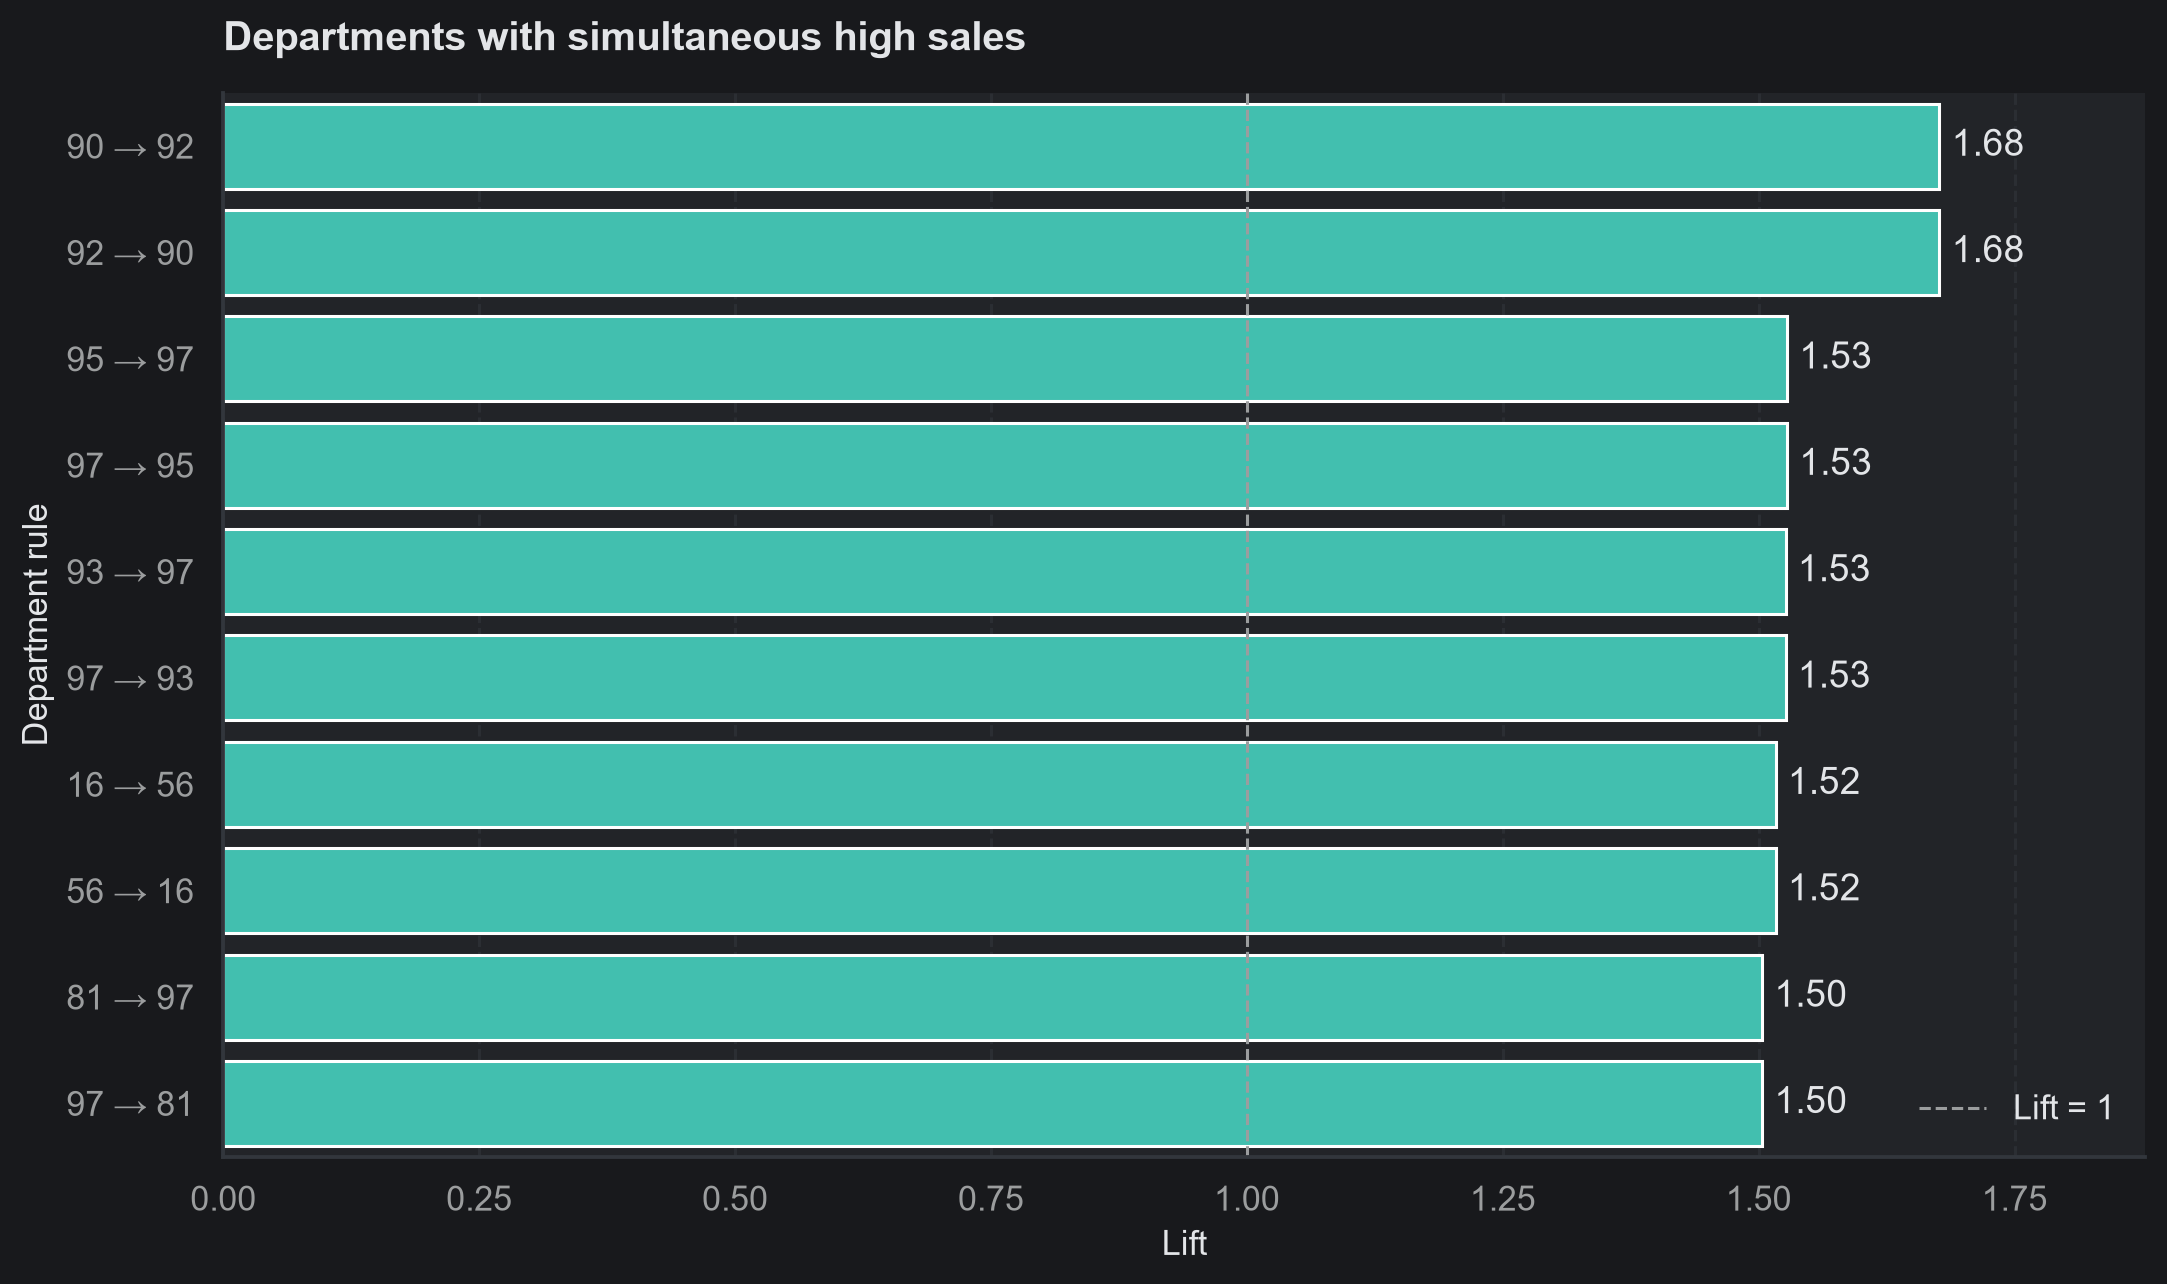

In [41]:
threshold = train.groupby(["Store", "Dept"]).Weekly_Sales.median().rename("TypicalSales")
proxy = train.join(threshold, on=["Store", "Dept"])
proxy["HighSales"] = (proxy.Weekly_Sales > proxy.TypicalSales).astype(float)
baskets = proxy.pivot(index=["Store", "Date"], columns="Dept", values="HighSales")
baskets = baskets.loc[:, baskets.notna().mean() >= .90]
rules = []
# Compare department pairs using weeks where both were observed.
for a, b in combinations(baskets.columns, 2):
    pair = baskets[[a, b]].dropna()
    probability_a = pair[a].mean()
    probability_b = pair[b].mean()
    support = (pair[a].eq(1) & pair[b].eq(1)).mean()
    if probability_a == 0 or probability_b == 0:
        continue
    lift = support / (probability_a * probability_b)
    # Check both directions because confidence depends on the starting department.
    for left, right in [(a, b), (b, a)]:
        starting_probability = pair[left].mean()
        confidence = support / starting_probability
        if support >= .10 and confidence >= .50 and lift > 1:
            rules.append([left, right, len(pair), support, confidence, lift])
rules = pd.DataFrame(rules, columns=["FromDept", "ToDept", "CoObservedWeeks", "Support", "Confidence", "Lift"])
rules = rules.sort_values(["Lift", "Support"], ascending=False).reset_index(drop=True)
display(rules.head(10))
if not rules.empty:
    top = rules.head(10).copy()
    top["Rule"] = top.FromDept.astype(str) + " → " + top.ToDept.astype(str)
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(data=top, x="Lift", y="Rule", color=TEAL, ax=ax)
    ax.bar_label(ax.containers[0], fmt="%.2f", padding=4)
    ax.axvline(1, color=CUSTOM_THEME["subtext"], linestyle="--", linewidth=1, label="Lift = 1")
    ax.margins(x=.12)
    ax.xaxis.grid(True)
    ax.yaxis.grid(False)
    ax.legend(frameon=False)
    save_chart("18_department_proxy", "Departments with simultaneous high sales", xlabel="Lift", ylabel="Department rule")

#### 1. Why did you pick the specific chart?

A horizontal bar chart makes the strongest department high-sales rules easy to compare and keeps the rule labels readable. Ranking by lift highlights pairs whose high-sales events occur together more often than expected from their individual rates.

#### 2. What is/are the insight(s) found from the chart?

The leading rule is department 90 → 92, with lift approximately 1.68. On the 5,355 co-observed store-weeks, support is about 0.412 and confidence is about 0.831. These are simultaneous above-typical department sales events; the reverse rule describes the same pair and should not be counted as separate evidence of customer purchasing behavior.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

The pair can suggest a coordinated-display or campaign idea after the department IDs are mapped to actual categories. A small controlled pilot is needed before assuming that promoting one department increases purchases in the other. Shared seasonality can generate lift, and expanding a campaign without checking incremental margin could reduce profitability.

## 7. ML Model Implementation
### Models, Chronological Cross-validation and Small Parameter Comparison
Model 1 is the store-department historical mean (no tunable parameters). Model 2 is a decision tree: easy to understand but may overfit. Model 3 is a random forest: averages trees to reduce instability. Compare two settings for each tree model rather than adding a complex search.

Use expanding windows: train through the original training end, validate the next eight weeks, then expand training to include those weeks and validate another eight. All rows in a week stay together. Select the lowest mean validation MAE; RMSE highlights large misses and holiday WMAE gives supplied holiday weeks five times the weight. MAPE is avoided because zero and negative sales make it misleading.

Predictions across an eight-week block use no new sales labels. Models with external indicators assume those inputs are available; the calendar/store-only comparison measures a more realistic option when external inputs are unknown.

Fold 1 | Historical mean | MAE 2,777.62
Fold 1 | Decision tree depth 8 | MAE 10,145.91
Fold 1 | Decision tree depth 14 | MAE 7,543.27
Fold 1 | Random forest depth 14 | MAE 7,322.88
Fold 1 | Random forest depth 20 | MAE 5,715.77
Fold 2 | Historical mean | MAE 2,554.04
Fold 2 | Decision tree depth 8 | MAE 9,738.82
Fold 2 | Decision tree depth 14 | MAE 7,264.26
Fold 2 | Random forest depth 14 | MAE 6,970.07
Fold 2 | Random forest depth 20 | MAE 5,415.65


,MAE,RMSE,Holiday_WMAE
model,,,
Historical mean,2665.828546,5538.431723,2665.828546
Random forest depth 20,5565.708927,8500.665632,5565.708927
Random forest depth 14,7146.471482,10060.516476,7146.471482
Decision tree depth 14,7403.764729,10446.481918,7403.764729
Decision tree depth 8,9942.368632,13872.759950,9942.368632


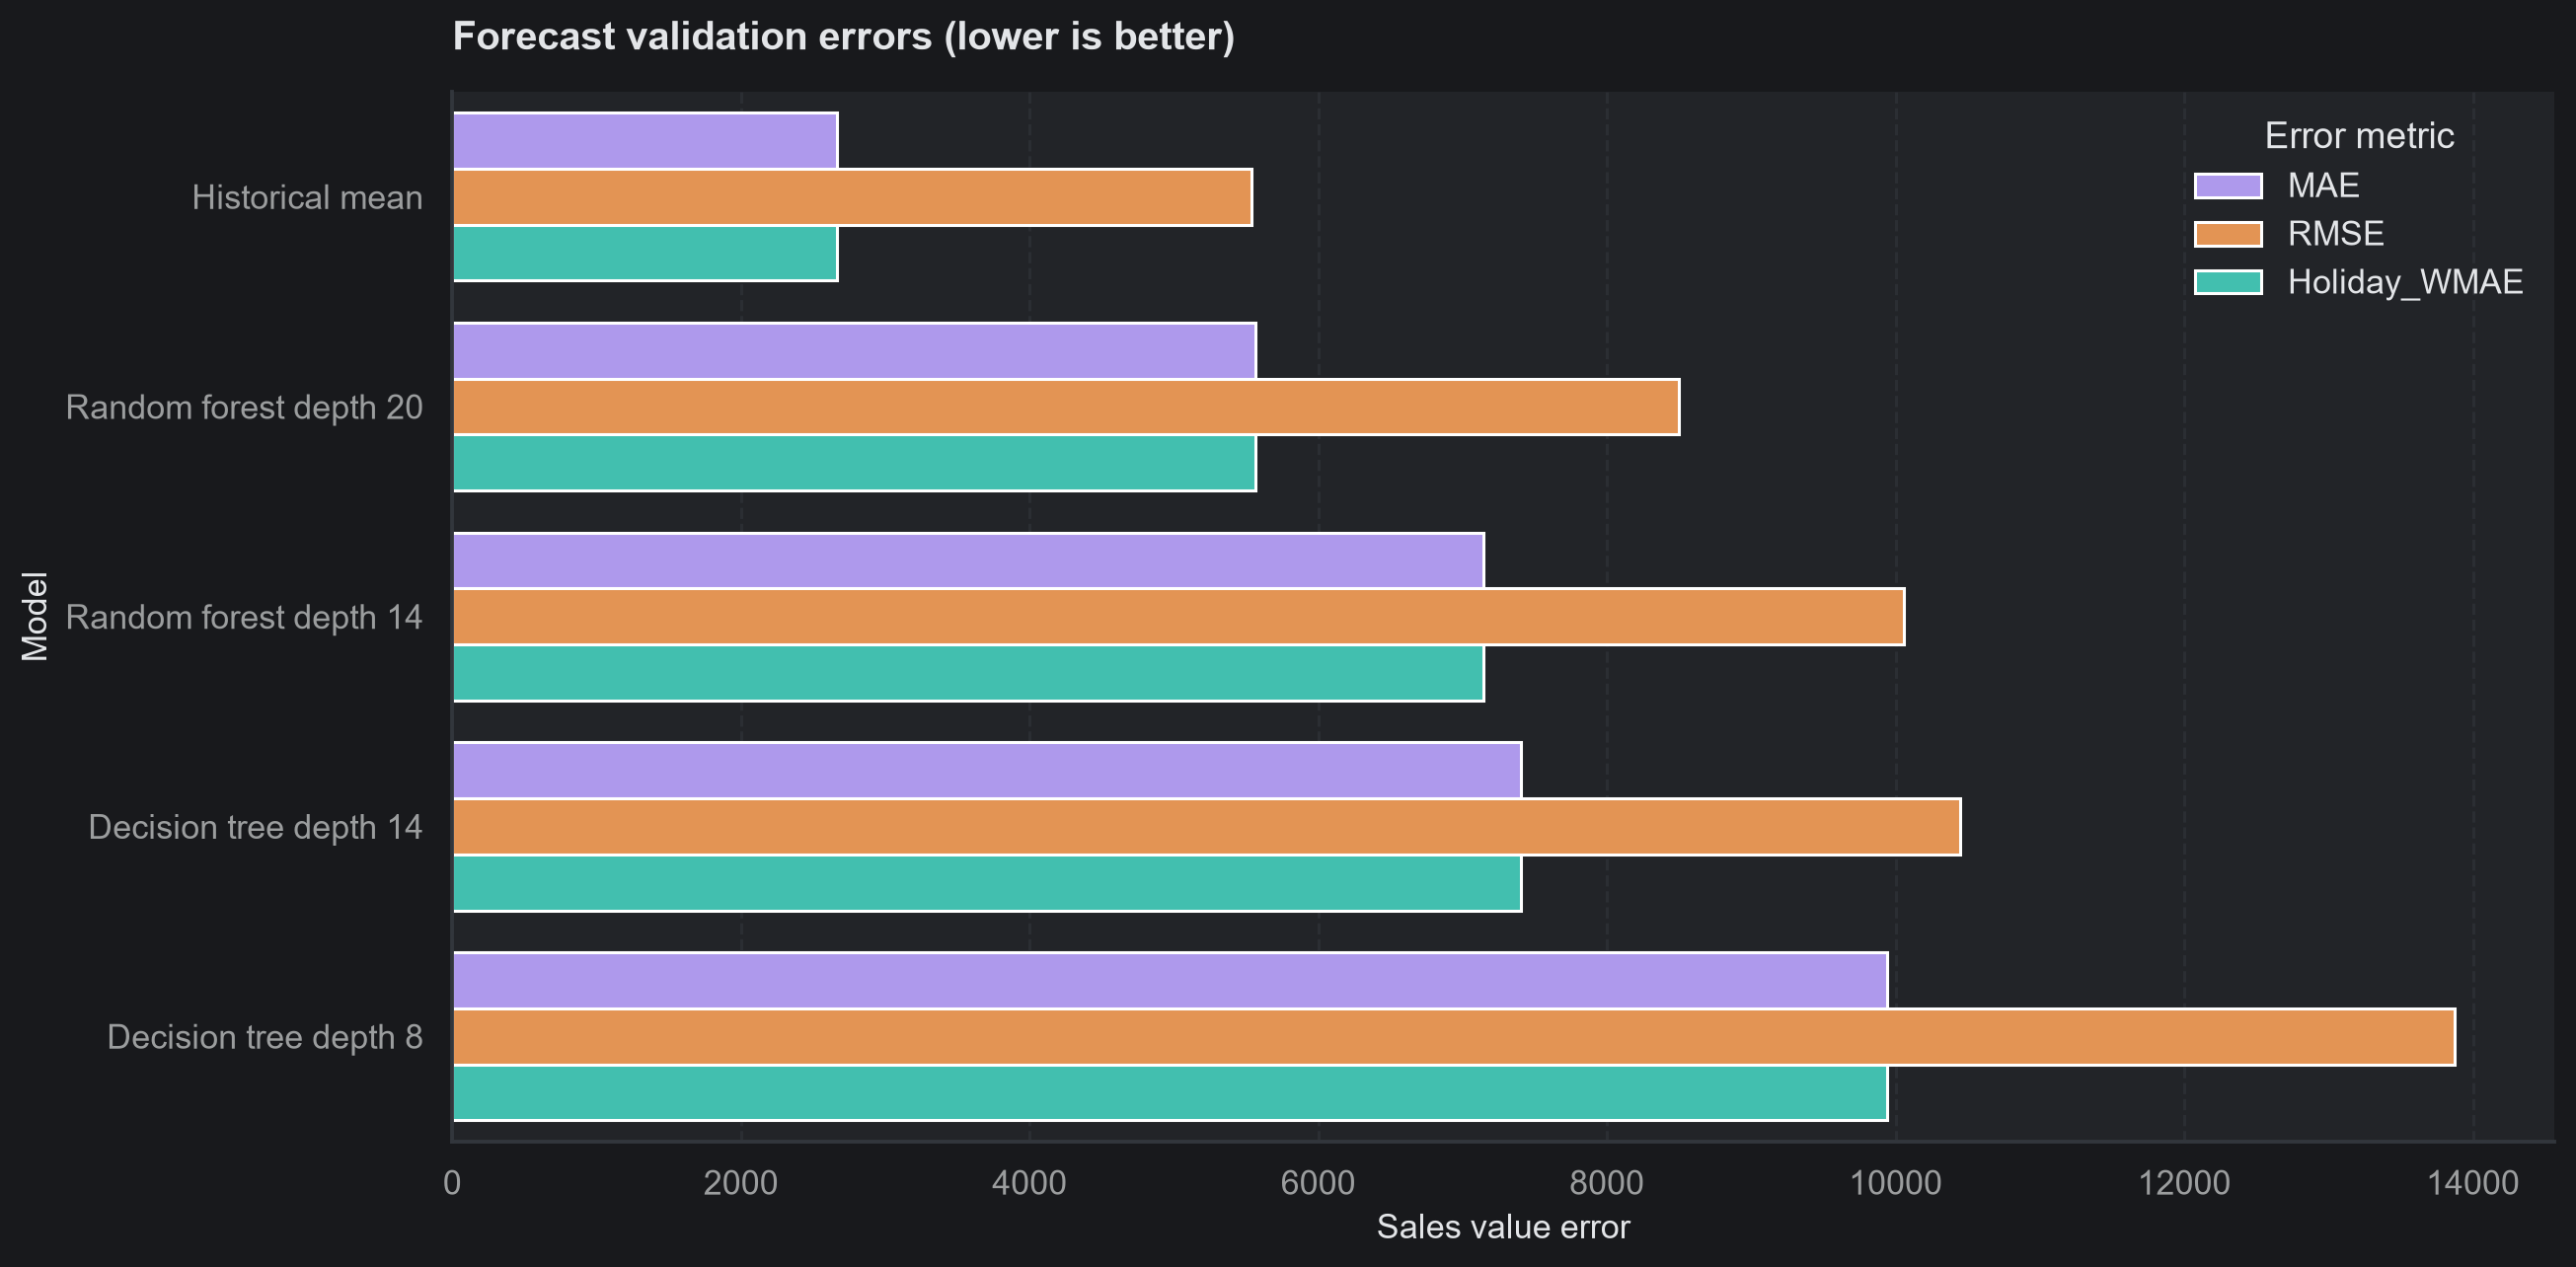

In [42]:
configs = [
    ("Historical mean", None),
    ("Decision tree depth 8", DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=SEED)),
    ("Decision tree depth 14", DecisionTreeRegressor(max_depth=14, min_samples_leaf=20, random_state=SEED)),
    ("Random forest depth 14", RandomForestRegressor(n_estimators=40, max_depth=14,
        min_samples_leaf=10, max_features=.8, n_jobs=-1, random_state=SEED)),
    ("Random forest depth 20", RandomForestRegressor(n_estimators=40, max_depth=20,
        min_samples_leaf=10, max_features=.8, n_jobs=-1, random_state=SEED))
]
cv_rows = []
for fold, (start, stop) in enumerate([(dates[-24], dates[-16]), (dates[-16], dates[-8])], 1):
    history = df[df.Date < start]
    future = df[(df.Date >= start) & (df.Date < stop)]
    for name, estimator in configs:
        if estimator is None:
            prediction = mean_forecast(history, future)
        else:
            fitted = make_pipeline(estimator)
            fitted.fit(history[predictor_cols], history.Weekly_Sales)
            prediction = fitted.predict(future[predictor_cols])
        result = metrics(future.Weekly_Sales, prediction, future.IsHoliday)
        cv_rows.append({"model": name, "fold": fold, **result})
        print(f"Fold {fold} | {name} | MAE {result['MAE']:,.2f}", flush=True)
cv_detail = pd.DataFrame(cv_rows)
cv_scores = cv_detail.groupby("model")[["MAE", "RMSE", "Holiday_WMAE"]].mean().sort_values("MAE")
display(cv_scores)
# Reshape the score table for a grouped seaborn chart.
validation_plot = cv_scores.reset_index().melt(
    id_vars="model", value_vars=["MAE", "RMSE", "Holiday_WMAE"],
    var_name="Metric", value_name="Error"
)
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=validation_plot, x="Error", y="model", hue="Metric",
            palette=[PURPLE, ORANGE, TEAL], errorbar=None, ax=ax)
ax.legend(title="Error metric", frameon=False, loc="upper right")
ax.xaxis.grid(True)
ax.yaxis.grid(False)
save_chart("19_model_validation", "Forecast validation errors (lower is better)",
           xlabel="Sales value error", ylabel="Model")

#### 1. Why did you pick the specific chart?

A grouped bar chart compares MAE, RMSE and holiday-weighted MAE across the forecasting configurations on the same sales-currency scale. Showing all tested methods together makes the baseline comparison and the larger-error sensitivity of RMSE easy to assess.

#### 2. What is/are the insight(s) found from the chart?

Historical store-department means have the lowest average validation MAE, at 2,665.83, compared with 5,565.71 for the best tested forest. Deeper settings improve on the shallower tree configurations, but neither tree family beats the baseline. Holiday-weighted MAE equals MAE because the validation blocks contain no supplied holiday weeks, so the chart does not establish holiday accuracy.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

The result supports selecting the simpler historical-mean method for the final assessment. Its lower measured error and straightforward explanation are more useful here than added model complexity. Relying on validation alone would still be risky, so the final test is assessed separately; none of these currency errors directly measures stock units or profit.

### Interpreting the validation result
Historical store-department means have the lowest mean validation MAE (2,665.83); the best tested forest has MAE 5,565.71. Deeper trees improve over the shallower versions, but neither tree family beats the simple baseline. With many one-hot department and store categories, these limited-depth models struggle to represent the store-department differences captured directly by the mean. This is a result of the tested configurations, not proof that tree models can never work.

The validation block has no supplied holiday weeks, so holiday WMAE equals MAE and cannot demonstrate holiday performance here. The final test includes a supplied holiday week; the separate longer-horizon block also provides seasonal context. The stated baseline-improvement criterion is not met by the tested ML models.

### Tuning Improvement and Business Interpretation
The following table compares the deeper setting with the shallower setting for each model. A positive MAE change means improvement; tuning can also make results worse. Historical means need no hyperparameter search. MAE expresses the average sales miss per department-week, RMSE emphasizes costly large misses, and holiday WMAE prioritizes holiday mistakes. These are sales-value errors, not inventory units or measured profit.

### Anomaly Handling and External-factor Check
Use only the first validation block for two small diagnostic experiments with a fixed decision tree. Compare raw versus training-IQR-clipped targets, and external versus calendar/store-only inputs. These diagnostics do not change the predefined model-selection process. Validation/test targets are never clipped.

In [21]:
tuning_rows = []
for family in ["Decision tree", "Random forest"]:
    shallow = cv_scores.loc[f"{family} depth " + ("8" if family == "Decision tree" else "14"), "MAE"]
    deep = cv_scores.loc[f"{family} depth " + ("14" if family == "Decision tree" else "20"), "MAE"]
    tuning_rows.append([family, shallow, deep, shallow - deep])
tuning = pd.DataFrame(tuning_rows, columns=["family", "initial_MAE", "deeper_MAE", "MAE_improvement"])
display(tuning)
probe_future = df[(df.Date >= dates[-24]) & (df.Date < dates[-16])]
train_bounds = train.join(bounds[["lower", "upper"]], on=["Store", "Dept"])
clipped_y = train_bounds.Weekly_Sales.clip(lower=train_bounds.lower, upper=train_bounds.upper)
diagnostics = []
for name, target, use_external in [
    ("Raw target + external inputs", train.Weekly_Sales, True),
    ("Clipped training target + external inputs", clipped_y, True),
    ("Raw target + calendar/store only", train.Weekly_Sales, False)
]:
    probe_model = make_pipeline(DecisionTreeRegressor(max_depth=14, min_samples_leaf=20, random_state=SEED), use_external)
    probe_model.fit(train[predictor_cols], target)
    pred = probe_model.predict(probe_future[predictor_cols])
    diagnostics.append({"experiment": name, **metrics(probe_future.Weekly_Sales, pred, probe_future.IsHoliday)})
diagnostics = pd.DataFrame(diagnostics)
display(diagnostics)
print("Retain raw targets in the main models; use clipping results as evidence for review, not automatic deletion.")

,family,initial_MAE,deeper_MAE,MAE_improvement
0,Decision tree,9942.368632,7403.764729,2538.603904
1,Random forest,7146.471482,5565.708927,1580.762554


,experiment,MAE,RMSE,Holiday_WMAE
0,Raw target + external inputs,7543.266831,10742.759009,7543.266831
1,Clipped training target + external inputs,7487.424780,10735.254328,7487.424780
2,Raw target + calendar/store only,7520.032912,10724.036164,7520.032912


Retain raw targets in the main models; use clipping results as evidence for review, not automatic deletion.


### Final Model Selection and Held-out Assessment
Select the configuration using validation MAE only. Refit on all weeks before the final eight test weeks and assess once on original test sales. Report test results against the historical-mean baseline without changing selection based on test performance. Segment and format error tables highlight where the overall average hides problems. Feature importance for tree models describes predictive usage, not causal impact.

,model,MAE,RMSE,Holiday_WMAE
0,Historical mean,2266.300421,4394.572233,2431.308812
1,Historical mean (selected),2266.300421,4394.572233,2431.308812


Selected on validation: Historical mean
Test MAE improvement over mean baseline: 0.0


,mean,count
Type,,
A,2731.458487,12080
B,2021.600980,9188
C,896.608848,2461


,mean,count
Segment,,
0,1461.227577,11303
1,2998.614791,12426


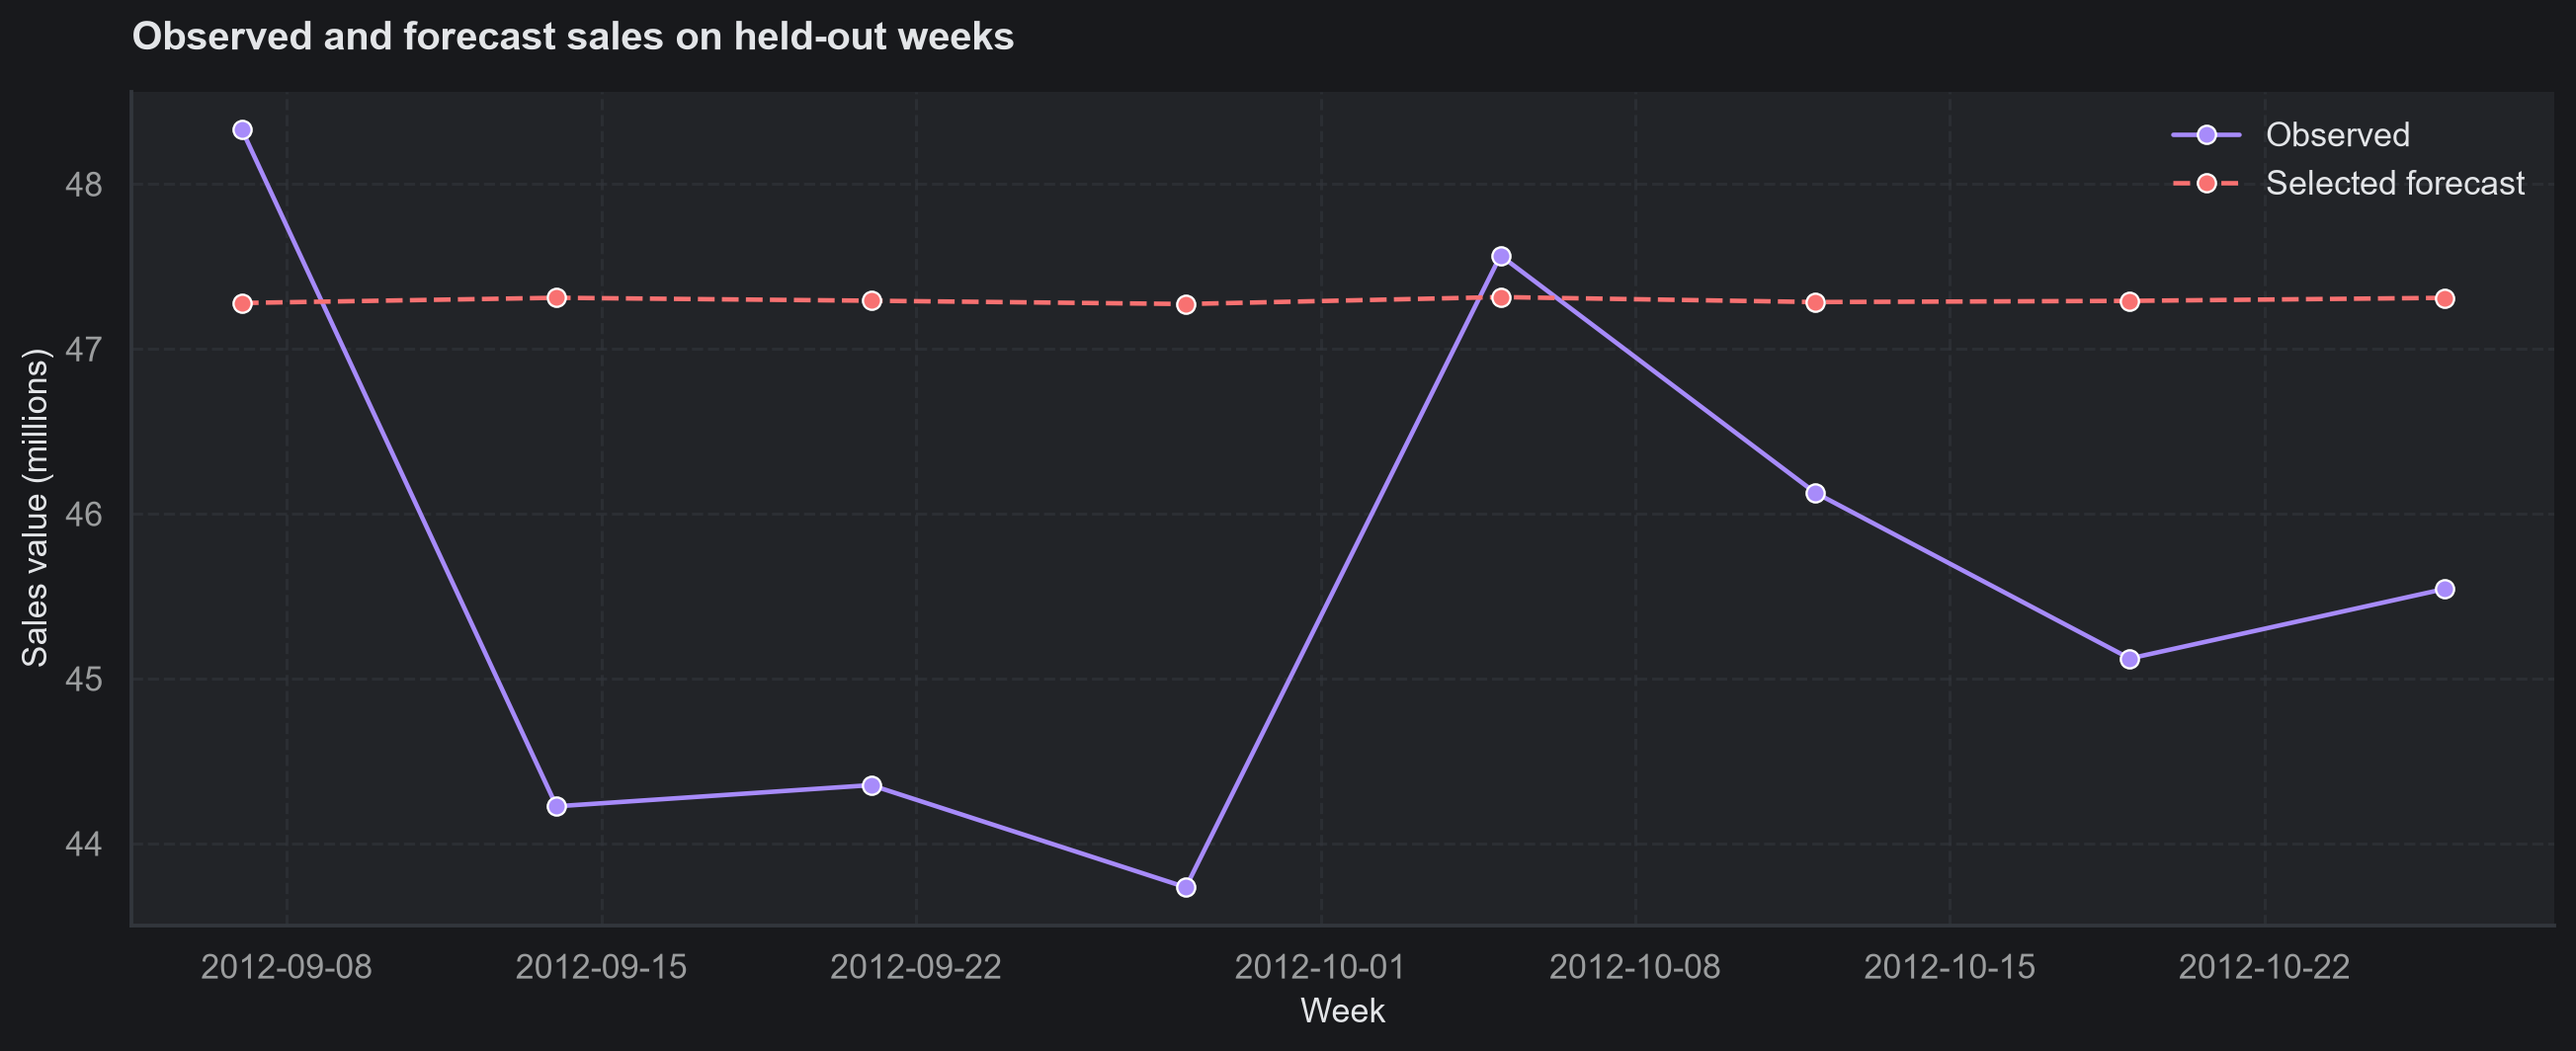

Historical means were best on validation; their explanation is each series' past average.


In [43]:
selected_name = cv_scores.index[0]
history = df[df.Date < test_start].copy()
selected_estimator = dict(configs)[selected_name]
if selected_estimator is None:
    final_model = None
    test_prediction = mean_forecast(history, test)
else:
    final_model = make_pipeline(selected_estimator)
    final_model.fit(history[predictor_cols], history.Weekly_Sales)
    test_prediction = final_model.predict(test[predictor_cols])
test_baseline = mean_forecast(history, test)
test_scores = pd.DataFrame([
    {"model": "Historical mean", **metrics(test.Weekly_Sales, test_baseline, test.IsHoliday)},
    {"model": selected_name + " (selected)", **metrics(test.Weekly_Sales, test_prediction, test.IsHoliday)}
])
display(test_scores)
print("Selected on validation:", selected_name)
print("Test MAE improvement over mean baseline:",
      round(mean_absolute_error(test.Weekly_Sales, test_baseline) - mean_absolute_error(test.Weekly_Sales, test_prediction), 2))
predictions = test[["Store", "Dept", "Date", "Type", "IsHoliday", "Weekly_Sales"]].copy()
predictions["Prediction"] = test_prediction
predictions["AbsoluteError"] = abs(predictions.Weekly_Sales - predictions.Prediction)
predictions["Segment"] = predictions.Store.map(store_profiles.Segment)
display(predictions.groupby("Type").AbsoluteError.agg(["mean", "count"]))
display(predictions.groupby("Segment").AbsoluteError.agg(["mean", "count"]))
forecast_plot = predictions.groupby("Date")[["Weekly_Sales", "Prediction"]].sum()
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(x=forecast_plot.index, y=forecast_plot.Weekly_Sales / 1e6,
             color=PURPLE, marker="o", label="Observed", ax=ax)
sns.lineplot(x=forecast_plot.index, y=forecast_plot.Prediction / 1e6,
             color=CORAL, marker="o", linestyle="--", label="Selected forecast", ax=ax)
ax.legend(frameon=False)
save_chart("20_test_forecast", "Observed and forecast sales on held-out weeks",
           xlabel="Week", ylabel="Sales value (millions)")
if final_model is not None:
    names = final_model.named_steps["preprocessing"].get_feature_names_out()
    importances = pd.Series(final_model.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
    display(importances.head(15))
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(x=importances.head(15).to_numpy(), y=importances.head(15).index, color=PURPLE, ax=ax)
    save_chart("21_feature_importance", "Top predictive features in selected tree model", xlabel="Impurity importance")
    print("Correlated inputs can share importance, and high-cardinality features may be favored.")
else:
    print("Historical means were best on validation; their explanation is each series' past average.")

#### 1. Why did you pick the specific chart?

A line chart compares observed and predicted chain sales in their actual weekly order over the final test period. This makes it easy to see whether the selected forecast follows changes in total sales and where it misses peaks or declines.

#### 2. What is/are the insight(s) found from the chart?

The selected historical-mean forecast is relatively flat, while observed weekly sales fluctuate. Its held-out department-week MAE is 2,266.30, RMSE is 4,394.57 and holiday-weighted MAE is 2,431.31. Because the selected method is the historical-mean baseline itself, it has no improvement over that baseline; the aggregate lines can also hide errors that offset across departments.

#### 3. Will the gained insights help creating a positive business impact? Are there any insights that lead to negative growth? Justify with specific reason.

The forecast provides a simple reference for weekly sales planning, but the visible variation supports reviewing seasonal periods and high-error departments more closely. Overprediction can encourage excessive stock commitments, while underprediction can create availability pressure. Store-format and segment error summaries should therefore accompany this chain-level view, and sales values require additional product information before inventory quantities can be set.

### Longer-Horizon Seasonal Forecast
Use an additional, explicitly labeled 26-week planning experiment ending before the primary validation and test periods. Compare a fixed historical mean with sales from exactly 52 weeks earlier (364 days), falling back to the historical mean for missing pairs. The entire training window ends before this block; the seasonal labels also predate its start. This simple seasonal baseline is understandable and requires no unknown future economic values. A 26-week result on one historical block is limited evidence, not a guarantee for future years.

In [23]:
# Test a 26-week forecast on an earlier period.
long_end = val_start
long_start = long_end - pd.Timedelta(weeks=26)
long_history = df[df.Date < long_start]
long_future = df[(df.Date >= long_start) & (df.Date < long_end)].copy()

# Move historical dates forward 52 weeks so they match the forecast dates.
last_year = long_history[["Store", "Dept", "Date", "Weekly_Sales"]].copy()
last_year["Date"] = last_year["Date"] + pd.Timedelta(weeks=52)
last_year = last_year.rename(columns={"Weekly_Sales": "SeasonalSales"})
seasonal_matches = long_future[["Store", "Dept", "Date"]].merge(
    last_year, on=["Store", "Dept", "Date"], how="left", validate="one_to_one"
)

long_mean = mean_forecast(long_history, long_future)
coverage = seasonal_matches["SeasonalSales"].notna().mean()
# Fall back to the historical average when last year's observation is missing.
long_seasonal = seasonal_matches["SeasonalSales"].fillna(pd.Series(long_mean)).to_numpy()
mean_scores = metrics(long_future.Weekly_Sales, long_mean, long_future.IsHoliday)
seasonal_scores = metrics(long_future.Weekly_Sales, long_seasonal, long_future.IsHoliday)
long_scores = pd.DataFrame(
    [mean_scores, seasonal_scores],
    index=["26-week historical mean", "26-week seasonal naive"]
)
display(long_scores)
print("26-week block:", long_future.Date.min(), "to", long_future.Date.max())
print(f"Exact 52-week seasonal coverage: {coverage:.1%}")

,MAE,RMSE,Holiday_WMAE
26-week historical mean,3384.779797,9599.643501,3917.005431
26-week seasonal naive,2063.445953,4622.947020,2159.531117


26-week block: 2011-11-18 00:00:00 to 2012-05-11 00:00:00
Exact 52-week seasonal coverage: 96.9%


## 8. Save and Reload the Model
Save the fitted model, feature list, date origin and historical-mean fallback. New inputs must use the same calendar features and predictor definitions. The reload check compares predictions on test inputs without their target column.

In [44]:
artifact = {
    "pipeline": final_model, "name": selected_name,
    "columns": predictor_cols, "date_origin": df.Date.min(),
    "series_means": history.groupby(["Store", "Dept"]).Weekly_Sales.mean(),
    "global_mean": history.Weekly_Sales.mean(), "trained_through": history.Date.max()
}
joblib.dump(artifact, MODEL / "sales_forecaster.joblib")
loaded = joblib.load(MODEL / "sales_forecaster.joblib")
unseen_inputs = test[predictor_cols].head(5)
if loaded["pipeline"] is not None:
    reload_predictions = loaded["pipeline"].predict(unseen_inputs)
else:
    # Join the saved store-department averages to the new inputs.
    saved_means = loaded["series_means"].rename("MeanSales").reset_index()
    matches = unseen_inputs[["Store", "Dept"]].merge(
        saved_means, on=["Store", "Dept"], how="left"
    )
    reload_predictions = matches["MeanSales"].fillna(loaded["global_mean"]).to_numpy()
np.testing.assert_allclose(reload_predictions, test_prediction[:5])
print("Reload check passed:", reload_predictions)
summary = {
    "sales_rows": len(df), "stores": int(df.Store.nunique()), "departments": int(df.Dept.nunique()),
    "start": str(df.Date.min().date()), "end": str(df.Date.max().date()),
    "selected_model": selected_name, "cluster_k": best_k,
    "silhouette": float(cluster_scores.silhouette.max()),
    "test_MAE": float(mean_absolute_error(test.Weekly_Sales, test_prediction)),
    "baseline_test_MAE": float(mean_absolute_error(test.Weekly_Sales, test_baseline)),
    "iqr_flags": int(audit.IQR_anomaly.sum()), "time_flags": int(audit.Time_anomaly.sum()),
    "proxy_rule_count": len(rules), "seasonal_coverage": float(coverage)
}
display(summary)

Reload check passed: [22570.53866667 46187.07881481 13194.87503704 37003.8977037
 24372.08244444]


{'sales_rows': 421570,
 'stores': 45,
 'departments': 81,
 'start': '2010-02-05',
 'end': '2012-10-26',
 'selected_model': 'Historical mean',
 'cluster_k': 2,
 'silhouette': 0.345427351950302,
 'test_MAE': 2266.3004212438464,
 'baseline_test_MAE': 2266.3004212438464,
 'iqr_flags': 7141,
 'time_flags': 26169,
 'proxy_rule_count': 1702,
 'seasonal_coverage': 0.9686548288855624}

## Conclusion and Business Strategy
Historical store-department means were selected for the final forecast. The recommendations below reflect the measured errors and store profiles.

- **Inventory:** use department-level forecasts as sales-value planning signals. Convert to units only with prices, product mix and lead-time data. Prioritize departments with large absolute errors and stores with high variability.
- **Anomalies:** review flagged weeks alongside the supplied holiday flag, markdown records, returns and data-feed logs. Preserve valid seasonal peaks; correct only verified errors.
- **Marketing:** profile store segments before choosing a campaign. High-sales and variable segments may need availability-focused messaging; smaller segments need tightly scoped promotions and conservative stock commitments. These are hypotheses to pilot.
- **Cross-selling:** map the strongest department proxy pairs to real category names, then run a small controlled campaign. Measure incremental margin, not merely joint high sales.
- **External conditions:** use planned markdowns and realistic weather/economic scenarios at forecast time. Observed historical indicators give conditional estimates and can overstate operational accuracy.
- **Monitoring:** review weekly MAE and holiday errors by store format, segment and department. Reassess when promotions, assortment or store operations change.
- **Limitations:** fewer than three years of data, missing promotions, unknown stockouts, anonymized departments, limited holiday labels and no customer baskets limit inference. Sales correlations do not establish causal effects. Multiple historical windows are more credible than a single score.


**Measured conclusion:** Historical mean was selected by chronological validation. Held-out MAE is **2,266.30**, compared with **2,266.30** for historical means. The best tested store segmentation uses **2 clusters** with silhouette **0.345**. These results support a pilot and error review; they do not establish profit improvements.